In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns
import math
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import umap
import random
from matplotlib.colors import ListedColormap, BoundaryNorm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

RANDOM_SEEDS = [42, 123, 2026]
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<div dir="rtl" align="right">
با توجه به مقادیر کد image_check, تصاویری که دارای انسان یا گونه‌های متفاوت در یک تصویر هستند را حذف می‌کنیم.
</div>

In [2]:
df = pd.read_csv("../inat_birds/dataset.csv")
df = df[df["img_check"] != "REMOVE"].reset_index(drop=True)

<div dir="rtl" align="right">
سپس تصاویری که داری bird_sharpness کمی هستند را حذف می‌کنیم بر اساس log_bird_sharpness.
</div>

Q1: 5.4467
Q3: 6.8222
IQR: 1.3755
Lower bound: 3.3835
Upper bound: 8.8855
Total low-sharpness outliers: 247
Displaying 50 random outliers.


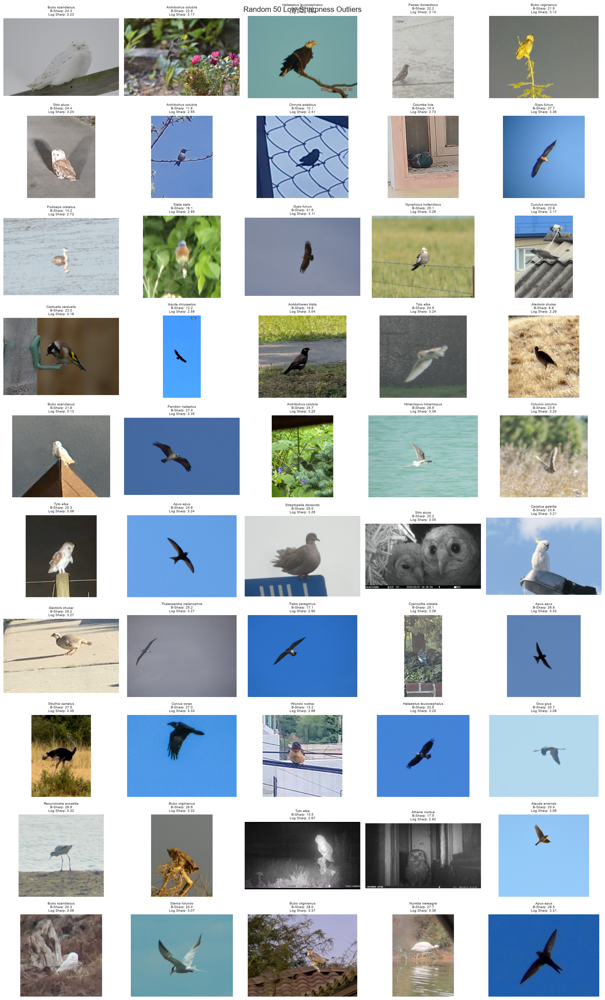

In [3]:
def show_iqr_outliers(df, n=100, cols=5, random_state=SEED):

    data = df[df["bird_num"] == 1].copy()

    data["log_bird_sharpness"] = np.log1p(
        data["bird_sharpness"]
    )

    Q1 = data["log_bird_sharpness"].quantile(0.25)
    Q3 = data["log_bird_sharpness"].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        data["log_bird_sharpness"] < lower_bound
    ].copy()

    print(f"Q1: {Q1:.4f}")
    print(f"Q3: {Q3:.4f}")
    print(f"IQR: {IQR:.4f}")
    print(f"Lower bound: {lower_bound:.4f}")
    print(f"Upper bound: {upper_bound:.4f}")
    print(f"Total low-sharpness outliers: {len(outliers)}")

    if outliers.empty:
        print("No outliers found.")
        return outliers

    sample = outliers.sample(
        n=min(n, len(outliers)),
        random_state=random_state
    )

    print(f"Displaying {len(sample)} random outliers.")

    rows = math.ceil(len(sample) / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(18, rows * 3)
    )

    axes = np.array(axes).flatten()

    for ax, (_, row) in zip(axes, sample.iterrows()):
        try:
            img = Image.open(
                "../inat_birds/" + row["image_path"]
            ).convert("RGB")

            ax.imshow(img)

            ax.set_title(
                f"{row['species_scientific']}\n"
                f"B-Sharp: {row['bird_sharpness']:.1f}\n"
                f"Log Sharp: {row['log_bird_sharpness']:.2f}",
                fontsize=7
            )

        except Exception:
            ax.text(
                0.5, 0.5, "Could not load",
                ha="center", va="center"
            )

        ax.axis("off")

    for ax in axes[len(sample):]:
        ax.axis("off")

    fig.suptitle(
        f"Random {len(sample)} Low-Sharpness Outliers",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

    return outliers


outliers = show_iqr_outliers(df, n=50)

In [4]:
df_before_quality_filter = df.copy()

bad_indices = outliers.index

df = df.drop(index=bad_indices).reset_index(drop=True)

print(f"Removed images: {len(bad_indices)}")
print(f"Remaining images: {len(df)}")

Removed images: 247
Remaining images: 48053


In [5]:
structure = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "missing": df.isna().sum().values,
    "unique_values": df.nunique().values
})

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

for i in range(0, len(structure), 20):
    display(structure.iloc[i:i+20])


,column,dtype,non_null,missing,unique_values
0,image_path,str,48053,0,48053
1,image_abspath,str,48053,0,48053
2,label_id,int64,48053,0,100
3,species_scientific,str,48053,0,100
4,taxon_id,int64,48053,0,100
5,common_name,str,48053,0,100
6,iconic_taxon,str,48053,0,1
7,selection_tier,str,48053,0,2
8,observation_id,int64,48053,0,48053
9,observation_uuid,str,48053,0,48053


,column,dtype,non_null,missing,unique_values
20,size_variant,str,48053,0,1
21,user_id,int64,48053,0,18057
22,user_login,str,48053,0,18058
23,observed_on,str,48053,0,4710
24,time_observed_at,str,46886,1167,46639
25,observed_on_string,str,48053,0,47242
26,observed_time_zone,str,48053,0,352
27,year,int64,48053,0,53
28,month,int64,48053,0,12
29,day,int64,48053,0,31


,column,dtype,non_null,missing,unique_values
40,obscured,bool,48053,0,2
41,place_guess,str,47575,478,27352
42,place_ids,str,47947,106,21663
43,quality_grade,str,48053,0,1
44,captive,bool,48053,0,1
45,identifications_count,int64,48053,0,22
46,num_id_agreements,int64,48053,0,21
47,num_id_disagreements,int64,48053,0,4
48,faves_count,int64,48053,0,17
49,comments_count,int64,48053,0,14


,column,dtype,non_null,missing,unique_values
60,file_size_bytes,int64,48053,0,46696
61,image_format,str,48053,0,2
62,exif_orientation,int64,48053,0,1
63,sha256,str,48053,0,48053
64,dhash,str,48053,0,48053
65,sharpness,float64,48053,0,43933
66,brightness,float64,48053,0,14064
67,contrast,float64,48053,0,7370
68,aspect_ratio,float64,48053,0,861
69,detector,str,48053,0,1


,column,dtype,non_null,missing,unique_values
80,img_check,str,48053,0,2
81,img_check_reasons,str,3475,44578,23
82,chk_human_score,float64,48053,0,404
83,chk_hand_held,float64,48053,0,563
84,chk_animal_score,float64,48053,0,309
85,chk_recapture,float64,48053,0,999
86,chk_device_contain,float64,48053,0,97
87,chk_p_display,float64,920,47133,44
88,chk_moire_z,float64,48053,0,53
89,chk_margin_z,float64,48053,0,949


<div dir="rtl" align="right">
ابتدا متغییر‌های زیر را از نظر درستی داده‌ها بررسی می‌کنیم:
</div>

In [6]:
check_cols = [
    "latitude", "longitude",
    "width", "height",
    "sharpness", "brightness", "contrast",
    "bird_conf", "bird_num", "bird_area_frac",
    "bird_sharpness"
]

df[check_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,47975.0,24.988983,32.864798,-78.585765,11.038673,38.668663,48.313286,80.848943
longitude,47975.0,3.821395,78.439047,-179.979811,-70.691385,4.806491,36.433694,178.814016
width,48053.0,942.022121,143.408753,385.000000,863.000000,1024.000000,1024.000000,1024.000000
height,48053.0,797.626745,158.590031,384.000000,683.000000,768.000000,1024.000000,1024.000000
sharpness,48053.0,1420.969813,1480.884856,25.060000,439.980000,916.850000,1859.940000,16129.570000
brightness,48053.0,130.465377,33.699849,20.170000,109.800000,128.280000,149.200000,239.950000
contrast,48053.0,42.637157,15.718985,8.020000,31.310000,41.980000,53.050000,110.440000
bird_conf,48053.0,0.938937,0.156606,0.300000,0.990000,0.997800,0.999000,1.000000
bird_num,48053.0,2.032610,2.612554,1.000000,1.000000,1.000000,2.000000,99.000000
bird_area_frac,48053.0,0.211442,0.155380,0.050000,0.091000,0.161230,0.286490,1.000000


In [7]:
checks = {
    "latitude_out_of_range": ~df["latitude"].between(-90, 90),
    "longitude_out_of_range": ~df["longitude"].between(-180, 180),
    "width_non_positive": df["width"] <= 0,
    "height_non_positive": df["height"] <= 0,
    "sharpness_negative": df["sharpness"] < 0,
    "brightness_negative": df["brightness"] < 0,
    "contrast_negative": df["contrast"] < 0,
    "bird_conf_out_of_range": ~df["bird_conf"].between(0, 1),
    "bird_num_invalid": (df["bird_num"] < 0) | (df["bird_num"] % 1 != 0),
    "bird_area_frac_out_of_range": ~df["bird_area_frac"].between(0, 1),
    "bird_sharpness_negative": df["bird_sharpness"] < 0
}

pd.Series({
    name: mask.sum()
    for name, mask in checks.items()
})

latitude_out_of_range          78
longitude_out_of_range         78
width_non_positive              0
height_non_positive             0
sharpness_negative              0
brightness_negative             0
contrast_negative               0
bird_conf_out_of_range          0
bird_num_invalid                0
bird_area_frac_out_of_range     0
bird_sharpness_negative         0
dtype: int64

<div dir="rtl" align="right">
که خب فقط longitude و latitude دارای مقادیر غیرممکن هستند که آن‌ها همان مقادیر گمشده هستند که بعدا به آن رسیدگی می‌شود.
</div>

In [8]:
missing = df[check_cols].isna().sum()

numeric_cols = df[check_cols].select_dtypes(include=np.number).columns
inf = np.isinf(df[numeric_cols]).sum()

pd.DataFrame({
    "missing": missing,
    "infinite": inf
})

,missing,infinite
latitude,78,0
longitude,78,0
width,0,0
height,0,0
sharpness,0,0
brightness,0,0
contrast,0,0
bird_conf,0,0
bird_num,0,0
bird_area_frac,0,0


<div dir="rtl" align="right">
حالا ویژگی‌های مربوط به مختصات هر پرنده را بررسی می‌کنیم که درنهایت می‌بینیم مشکلی ندارند.
</div>

In [9]:
bbox_cols = ["bird_x1", "bird_y1", "bird_x2", "bird_y2"]

bbox_checks = {
    "x1_greater_equal_x2": df["bird_x1"] >= df["bird_x2"],
    "y1_greater_equal_y2": df["bird_y1"] >= df["bird_y2"],
    "x1_negative": df["bird_x1"] < 0,
    "y1_negative": df["bird_y1"] < 0,
    "x2_above_width": df["bird_x2"] > df["width"],
    "y2_above_height": df["bird_y2"] > df["height"]
}

pd.Series({
    name: mask.sum()
    for name, mask in bbox_checks.items()
})

x1_greater_equal_x2    0
y1_greater_equal_y2    0
x1_negative            0
y1_negative            0
x2_above_width         0
y2_above_height        0
dtype: int64

<div dir="rtl" align="right">
بررسی می‌کنیم تمام تصاویر دارای هش‌های متفاوتی باشند.
</div>

In [10]:
print("Duplicate SHA256:", df["sha256"].duplicated().sum())

print("Duplicate dhash:", df["dhash"].duplicated().sum())

Duplicate SHA256: 0
Duplicate dhash: 0


In [11]:
sha_label_counts = (
    df.groupby("sha256")["label_id"]
    .nunique()
)

print(
    "Images with conflicting labels:",
    (sha_label_counts > 1).sum()
)

Images with conflicting labels: 0


<div dir="rtl" align="right">
نمودار‌های جدید:
</div>

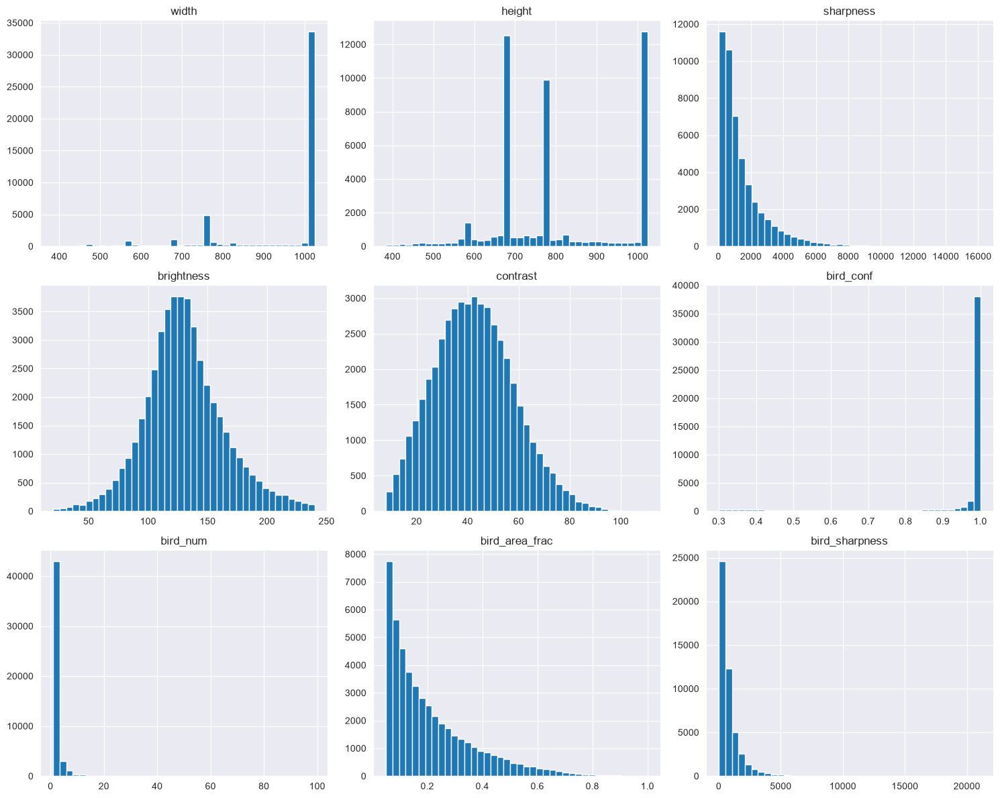

In [12]:
cols = [
    "width", "height",
    "sharpness", "brightness", "contrast",
    "bird_conf", "bird_num",
    "bird_area_frac", "bird_sharpness"
]

df[cols].hist(
    figsize=(15, 12),
    bins=40
)

plt.tight_layout()
plt.show()

<div dir="rtl" align="right">
بررسی می‌کنیم تمام time_zone ها معتبر باشند. که چنین هست غیر از مقادیر گمشده برای time_observed_at.
</div>

In [13]:
from datetime import datetime
from zoneinfo import ZoneInfo

def check_timezone(timestamp, timezone):
    try:
        recorded = datetime.fromisoformat(timestamp)
        expected = recorded.astimezone(
            ZoneInfo(timezone)
        )

        return (
            "match"
            if recorded.utcoffset() == expected.utcoffset()
            else "mismatch"
        )

    except (ValueError, TypeError, KeyError):
        return "invalid"

df["timezone_check"] = df.apply(
    lambda r: check_timezone(
        r["time_observed_at"],
        r["observed_time_zone"]
    ),
    axis=1
)

print(df["timezone_check"].value_counts(dropna=False))

timezone_check
match      46886
invalid     1167
Name: count, dtype: int64


<div dir="rtl" align="right">
مهندسی ویژگی‌های جدید (Feature Engineering)

به‌منظور استخراج اطلاعات مفیدتر از داده‌های اولیه، مجموعه‌ای از ویژگی‌های زمانی، جغرافیایی و مرتبط با کیفیت تصاویر ساخته شد.

در بخش زمانی، ویژگی‌های ساعت و ماه با استفاده از توابع سینوس و کسینوس به نمایش چرخه‌ای تبدیل شدند تا پیوستگی مقادیر ابتدا و انتهای بازه‌ها حفظ شود؛ برای مثال، ساعت ۲۳ به ساعت ۰ نزدیک است. همچنین ویژگی `has_hour` مشخص می‌کند که آیا ساعت ثبت تصویر موجود بوده است یا خیر. علاوه بر این، روز سال (`day_of_year`) و نمایش چرخه‌ای آن با استفاده از سینوس و کسینوس محاسبه شدند تا الگوهای فصلی قابل شناسایی باشند.

در بخش جغرافیایی، مختصات عرض و طول جغرافیایی به سه ویژگی `geo_x`، `geo_y` و `geo_z` تبدیل شدند. این تبدیل، موقعیت جغرافیایی را به‌صورت مختصات سه‌بعدی روی کره زمین نمایش می‌دهد. همچنین ویژگی `geo_missing` برای مشخص کردن نمونه‌های فاقد اطلاعات مکانی ایجاد شد.

در بخش ویژگی‌های تصویری، برای کاهش تأثیر مقادیر بسیار بزرگ، تبدیل لگاریتمی `log1p` روی ویژگی‌های `sharpness`، `bird_sharpness` و `bird_num` اعمال شد. همچنین نسبت وضوح پرنده به وضوح کل تصویر (`bird_sharp_ratio`) محاسبه شد تا کیفیت نسبی ناحیه حاوی پرنده بررسی شود. ویژگی `bird_area_frac` نیز برای نمایش سهم ناحیه اشغال‌شده توسط پرنده در تصویر مورد استفاده قرار گرفت.

در نهایت، آمار توصیفی ویژگی‌های انتخاب‌شده با استفاده از `describe()` بررسی شد تا شناخت اولیه‌ای از توزیع و مقادیر آن‌ها به دست آید.
</div>

In [14]:
df["hour_sin"] = np.where(df["time_observed_at"].notna(), np.sin(2 * np.pi * df["hour"] / 24), 0)
df["hour_cos"] = np.where(df["time_observed_at"].notna(), np.cos(2 * np.pi * df["hour"] / 24), 0)
df["month_sin"] = np.where(df["month"].notna(), np.sin(2 * np.pi * df["month"] / 12), 0)
df["month_cos"] = np.where(df["month"].notna(), np.cos(2 * np.pi * df["month"] / 12), 0)
df["has_hour"] = np.where(df["time_observed_at"].notna(), 1, 0)

df["day_of_year"] = pd.to_datetime(df["observed_on"]).dt.day_of_year
df["day_of_year_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_of_year_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

lat = np.radians(df["latitude"])
lon = np.radians(df["longitude"])

df["geo_x"] = (np.cos(lat) * np.cos(lon)).fillna(0)
df["geo_y"] = (np.cos(lat) * np.sin(lon)).fillna(0)
df["geo_z"] = np.sin(lat).fillna(0)
df["geo_missing"] = (df[["latitude", "longitude"]].isna().any(axis=1).astype(int))

df["log_sharpness"] = np.log1p(df["sharpness"])
df["log_bird_sharpness"] = np.log1p(df["bird_sharpness"])
df["bird_sharp_ratio"] = df["bird_sharpness"] / (df["sharpness"] + 1e-6)
df["bird_area_frac"] = df["bird_area_frac"]
df["log_bird_num"] = np.log1p(df["bird_num"])

features = [
    "hour_sin", "hour_cos", "month_sin", "month_cos", "has_hour",
    "day_of_year", "day_of_year_sin", "day_of_year_cos",
    "geo_x", "geo_y", "geo_z",
    "log_sharpness",
    "log_bird_sharpness",
    "bird_sharp_ratio",
    "log_bird_num"
]

df[features].describe().T

,count,mean,std,min,25%,50%,75%,max
hour_sin,48053.0,-0.091831,0.666256,-1.000000,-0.707107,0.000000e+00,0.500000,1.000000
hour_cos,48053.0,-0.563112,0.454206,-1.000000,-0.965926,-7.071068e-01,-0.258819,1.000000
month_sin,48053.0,0.003252,0.700613,-1.000000,-0.500000,1.224647e-16,0.500000,1.000000
month_cos,48053.0,-0.052002,0.711651,-1.000000,-0.866025,-1.836970e-16,0.500000,1.000000
has_hour,48053.0,0.975714,0.153936,0.000000,1.000000,1.000000e+00,1.000000,1.000000
day_of_year,48053.0,182.433168,102.799498,1.000000,97.000000,1.790000e+02,269.000000,366.000000
day_of_year_sin,48053.0,0.019460,0.702789,-0.999999,-0.689796,4.514102e-02,0.711276,0.999986
day_of_year_cos,48053.0,-0.047009,0.709592,-0.999979,-0.757220,-8.483488e-02,0.665287,0.999991
geo_x,48053.0,0.239983,0.497521,-0.957812,-0.126907,4.045443e-01,0.643005,0.995657
geo_y,48053.0,-0.026360,0.531354,-0.999984,-0.639396,5.221502e-02,0.418315,0.983314


<div dir="rtl" align="right">
حالا برای هر گونه, یک dhash_group اختصاص می‌دهیم بر اساس فاصله‌ی hamming.
</div>

In [15]:
HAMMING_THRESHOLD = 20

df = df.reset_index(drop=True).copy()
df["dhash_group"] = -1

near_pairs = []

class UnionFind:
    def __init__(self, n):
        self.parent = np.arange(n)
        self.rank = np.zeros(n, dtype=int)

    def find(self, x):
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)

        if ra == rb:
            return

        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra

        self.parent[rb] = ra

        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1


# Assign globally unique numeric group IDs
group_counter = 0

for species, group in df.groupby("species_scientific"):

    positions = group.index.to_numpy()
    hashes = [int(h, 16) for h in group["dhash"]]

    n = len(hashes)
    uf = UnionFind(n)

    # Compare every pair within the same species
    for i in range(n):
        for j in range(i + 1, n):

            distance = (hashes[i] ^ hashes[j]).bit_count()

            if distance <= HAMMING_THRESHOLD:

                uf.union(i, j)

                near_pairs.append({
                    "species": species,
                    "row_i": positions[i],
                    "row_j": positions[j],
                    "hamming_distance": distance
                })

    # Find connected components
    roots = [uf.find(i) for i in range(n)]

    unique_roots = sorted(set(roots))

    root_to_group = {
        root: group_counter + idx
        for idx, root in enumerate(unique_roots)
    }

    # Assign numeric group IDs
    df.loc[positions, "dhash_group"] = [
        root_to_group[root] for root in roots
    ]

    group_counter += len(unique_roots)


# Ensure integer dtype
df["dhash_group"] = df["dhash_group"].astype("int64")

# Convert pair records to DataFrame
near_pairs = pd.DataFrame(near_pairs)

# Group statistics
group_sizes = df["dhash_group"].value_counts()

multi_groups = group_sizes[group_sizes > 1]

print("Hamming threshold:", HAMMING_THRESHOLD)
print("Total images:", len(df))
print("Total DHash groups:", df["dhash_group"].nunique())
print("Number of near-duplicate pairs:", len(near_pairs))

print(
    "Total images in multi-image groups:",
    multi_groups.sum()
)

print(
    "Number of multi-image groups:",
    len(multi_groups)
)

print("\nGroup size distribution:")
print(multi_groups.describe())

print("\nLargest groups:")
print(multi_groups.head(20))

print("\nDHash group dtype:", df["dhash_group"].dtype)


Hamming threshold: 20
Total images: 48053
Total DHash groups: 47850
Number of near-duplicate pairs: 357
Total images in multi-image groups: 240
Number of multi-image groups: 37

Group size distribution:
count    37.000000
mean      6.486486
std       9.509123
min       2.000000
25%       2.000000
50%       3.000000
75%       5.000000
max      51.000000
Name: count, dtype: float64

Largest groups:
dhash_group
4300     51
4853     26
1441     20
19286    19
19562    14
22987    13
27726    10
31701     7
24926     7
41385     5
22564     5
24061     4
19585     3
22947     3
22948     3
39719     3
20610     3
6712      3
28713     3
12545     3
Name: count, dtype: int64

DHash group dtype: int64


Group ID: 4300
Species: Apus apus
Number of images: 51


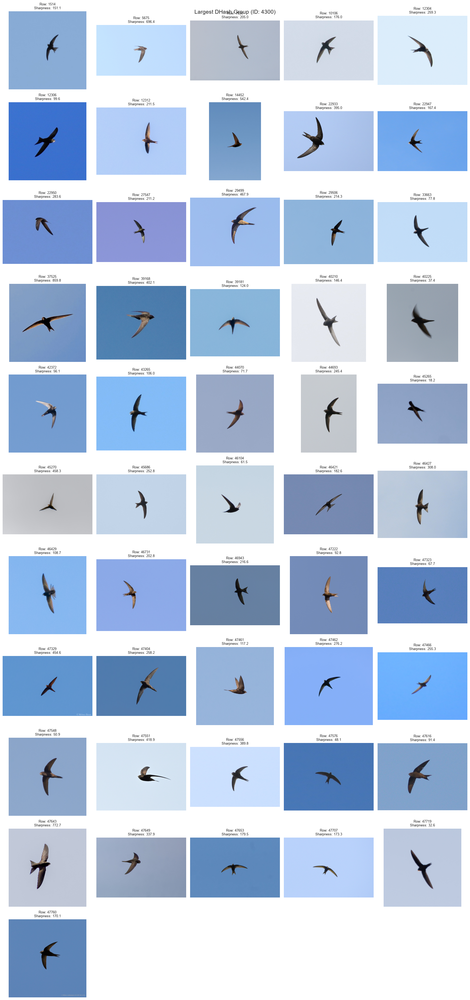

In [16]:
largest_group_id = df["dhash_group"].value_counts().idxmax()

group_df = df[df["dhash_group"] == largest_group_id].copy()

print("Group ID:", largest_group_id)
print("Species:", group_df["species_scientific"].iloc[0])
print("Number of images:", len(group_df))

# Display images
n = len(group_df)
cols = 5
rows = math.ceil(n / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(18, rows * 3.5)
)

axes = np.array(axes).flatten()

for ax, (_, row) in zip(axes, group_df.iterrows()):
    try:
        img = Image.open(
            "../inat_birds/" + row["image_path"]
        ).convert("RGB")

        ax.imshow(img)

        ax.set_title(
            f"Row: {row.name}\n"
            f"Sharpness: {row['bird_sharpness']:.1f}",
            fontsize=9
        )

    except Exception:
        ax.text(
            0.5, 0.5,
            "Could not load",
            ha="center",
            va="center"
        )

    ax.axis("off")

# Hide unused axes
for ax in axes[n:]:
    ax.axis("off")

fig.suptitle(
    f"Largest DHash Group (ID: {largest_group_id})",
    fontsize=15
)

plt.tight_layout()
plt.show()

Group ID: 19585
Species: Falco tinnunculus
Number of images: 3


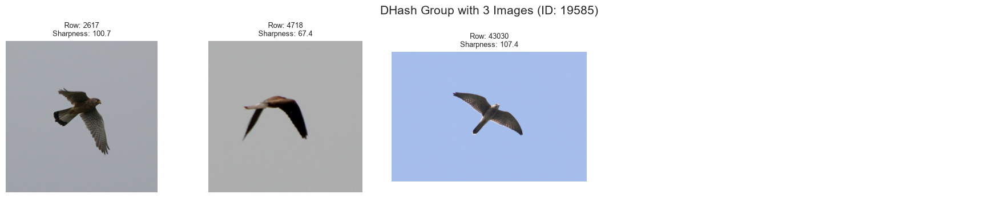

In [17]:
group_sizes = df["dhash_group"].value_counts()

candidate_groups = group_sizes[group_sizes == 3]

if candidate_groups.empty:
    print("No DHash group with exactly 3 images found.")

else:
    selected_group_id = candidate_groups.index[0]

    group_df = df[
        df["dhash_group"] == selected_group_id
    ].copy()

    print("Group ID:", selected_group_id)
    print("Species:", group_df["species_scientific"].iloc[0])
    print("Number of images:", len(group_df))

    # Display images
    n = len(group_df)
    cols = 5
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(18, rows * 3.5)
    )

    axes = np.array(axes).flatten()

    for ax, (_, row) in zip(axes, group_df.iterrows()):
        try:
            img = Image.open(
                "../inat_birds/" + row["image_path"]
            ).convert("RGB")

            ax.imshow(img)

            ax.set_title(
                f"Row: {row.name}\n"
                f"Sharpness: {row['bird_sharpness']:.1f}",
                fontsize=9
            )

        except Exception:
            ax.text(
                0.5, 0.5,
                "Could not load",
                ha="center",
                va="center"
            )

        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(
        f"DHash Group with 3 Images (ID: {selected_group_id})",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


In [18]:
id_cols = [
    "image_path", "observation_id", "user_id",
    "photo_url", "sha256", "dhash", "dhash_group"
]

label_cols = [
    "label_id", "species_scientific", "common_name"
]

meta_cols = [
    "year",
    "month_sin", "month_cos",
    "day_of_year_sin", "day_of_year_cos",
    "hour_sin", "hour_cos", "has_hour",
    "geo_x", "geo_y", "geo_z", "geo_missing"
]

image_stat_cols = [
    "width", "height",
    "sharpness", "brightness", "contrast",
    "bird_conf", "bird_num",
    "bird_x1", "bird_y1", "bird_x2", "bird_y2",
    "bird_area_frac", "bird_sharpness",
    "log_sharpness",
    "log_bird_sharpness",
    "bird_sharp_ratio",
    "log_bird_num"
]

analysis_only = [
    "latitude", "longitude",
    "day_of_year",
    "positional_accuracy", "obscured",
    "life_stage", "sex",
    "selection_tier", "time_observed_at",
    "observed_time_zone", "photo_license",
    "observed_on"
]
keep = id_cols + label_cols + meta_cols + image_stat_cols + analysis_only

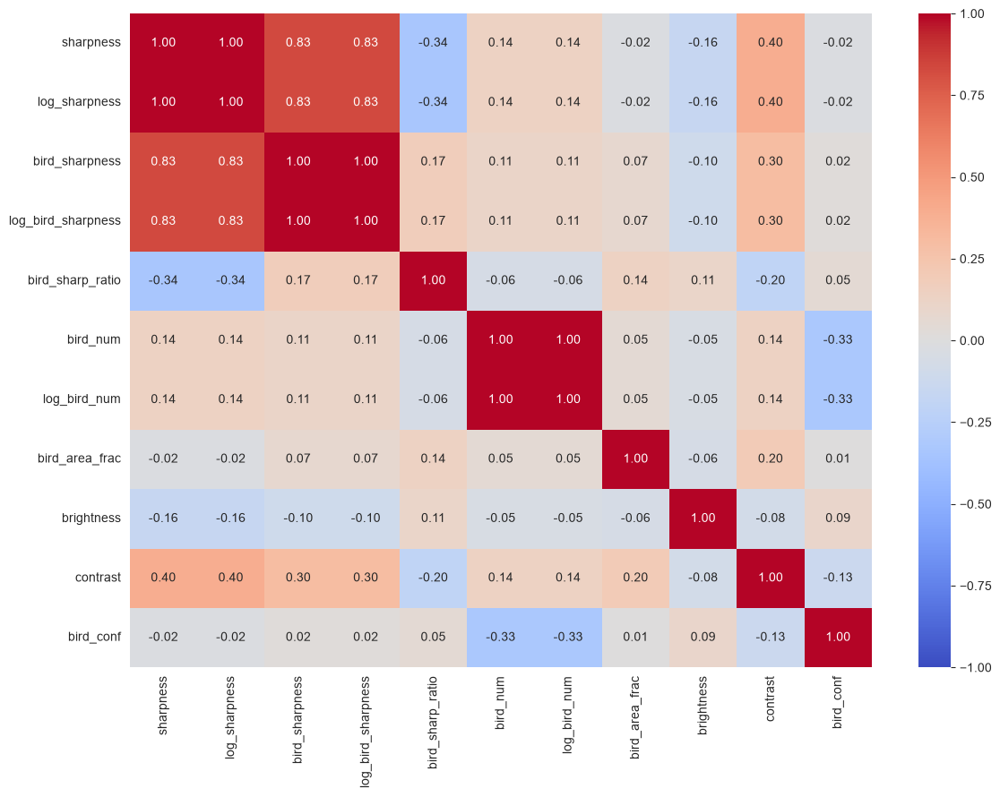

In [19]:
corr_cols = [
    "sharpness", "log_sharpness",
    "bird_sharpness", "log_bird_sharpness",
    "bird_sharp_ratio",
    "bird_num", "log_bird_num",
    "bird_area_frac",
    "brightness", "contrast",
    "bird_conf"
]

corr = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.tight_layout()
plt.show()

In [20]:
df["positional_accuracy"] = (
    df.groupby("species_scientific")["positional_accuracy"]
      .transform(lambda x: x.fillna(x.median()))
)

print("Remaining missing values:",
      df["positional_accuracy"].isna().sum())

Remaining missing values: 0


In [21]:
df = df[keep].copy()

print("=" * 60)
print("GENERAL OVERVIEW")
print("=" * 60)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print(f"Duplicate rows: {df.duplicated().sum():,}")

overview = pd.DataFrame(index=df.columns)

overview["dtype"] = df.dtypes.astype(str)
overview["missing"] = df.isna().sum()
overview["missing_%"] = (overview["missing"] / len(df) * 100).round(2)
overview["unique"] = df.nunique(dropna=True)

numeric_cols = df.select_dtypes(include=np.number).columns

overview["min"] = np.nan
overview["max"] = np.nan
overview["mean"] = np.nan
overview["median"] = np.nan
overview["std"] = np.nan
overview["inf_count"] = 0

for col in numeric_cols:
    s = df[col]

    overview.loc[col, "min"] = s.min()
    overview.loc[col, "max"] = s.max()
    overview.loc[col, "mean"] = s.mean()
    overview.loc[col, "median"] = s.median()
    overview.loc[col, "std"] = s.std()

    overview.loc[col, "inf_count"] = np.isinf(s).sum()

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)

display(overview)

print("\n" + "=" * 60)
print("CATEGORICAL COLUMNS")
print("=" * 60)

categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(10))


GENERAL OVERVIEW
Rows: 48,053
Columns: 51
Duplicate rows: 0


,dtype,missing,missing_%,unique,min,max,mean,median,std,inf_count
image_path,str,0,0.00,48053,NaN,NaN,NaN,NaN,NaN,0
observation_id,int64,0,0.00,48053,17075.000000,4.118431e+08,3.352749e+08,3.560589e+08,7.935082e+07,0
user_id,int64,0,0.00,18057,28.000000,1.120042e+07,5.631958e+06,5.733359e+06,3.514009e+06,0
photo_url,str,0,0.00,48053,NaN,NaN,NaN,NaN,NaN,0
sha256,str,0,0.00,48053,NaN,NaN,NaN,NaN,NaN,0
dhash,str,0,0.00,48053,NaN,NaN,NaN,NaN,NaN,0
dhash_group,int64,0,0.00,47850,0.000000,4.784900e+04,2.388315e+04,2.386100e+04,1.381702e+04,0
label_id,int64,0,0.00,100,0.000000,9.900000e+01,4.955505e+01,4.900000e+01,2.888075e+01,0
species_scientific,str,0,0.00,100,NaN,NaN,NaN,NaN,NaN,0
common_name,str,0,0.00,100,NaN,NaN,NaN,NaN,NaN,0



CATEGORICAL COLUMNS

image_path
image_path
images/Struthio_camelus/610424887.jpg    1
images/Struthio_camelus/610158916.jpg    1
images/Struthio_camelus/609766751.jpg    1
images/Struthio_camelus/612989307.jpg    1
images/Struthio_camelus/474117753.jpg    1
images/Struthio_camelus/467234979.jpg    1
images/Struthio_camelus/467240577.jpg    1
images/Struthio_camelus/465907490.jpg    1
images/Struthio_camelus/439852043.jpg    1
images/Struthio_camelus/746832485.jpg    1
Name: count, dtype: int64

photo_url
photo_url
https://inaturalist-open-data.s3.amazonaws.com/photos/610424887/large.jpg     1
https://inaturalist-open-data.s3.amazonaws.com/photos/610158916/large.jpg     1
https://inaturalist-open-data.s3.amazonaws.com/photos/609766751/large.jpg     1
https://inaturalist-open-data.s3.amazonaws.com/photos/612989307/large.jpg     1
https://inaturalist-open-data.s3.amazonaws.com/photos/474117753/large.jpeg    1
https://inaturalist-open-data.s3.amazonaws.com/photos/467234979/large.jpeg    1

In [22]:
df.to_csv("../inat_birds/dataset_slim.csv", index=False)

# Metadata PCA

<div dir="rtl" style="text-align: right;">

## PCA

برای کاهش ابعاد داده‌ها و بررسی میزان اطلاعات حفظ‌شده، الگوریتم PCA روی سه مجموعه ویژگی Metadata، Image Statistics و Combined اجرا شد. قبل از اجرای PCA، ویژگی‌ها با استفاده از StandardScaler استانداردسازی شدند.

هدف این بود که ببینیم با کاهش تعداد ویژگی‌ها، چه مقدار از واریانس داده‌ها همچنان حفظ می‌شود.

### نتایج

**۱. Metadata**

برای حفظ ۹۵٪ واریانس داده‌ها، به ۹ مؤلفه اصلی نیاز بود. همچنین با استفاده از ۱۰ مؤلفه، تقریباً تمام واریانس داده‌ها حفظ شد.

**۲. Image Statistics**

در این مجموعه، ۱۲ مؤلفه اصلی توانستند ۹۵٪ واریانس داده‌ها را حفظ کنند.

**۳. Combined**

در مجموعه ترکیبی، از مجموع ۲۹ ویژگی، با استفاده از ۲۱ مؤلفه اصلی می‌توان ۹۵٪ واریانس داده‌ها را حفظ کرد. بنابراین، تعداد ابعاد حدود ۲۷.۶٪ کاهش پیدا کرد.

### جمع‌بندی

نتایج نشان می‌دهد که هر سه مجموعه ویژگی تا حد قابل قبولی قابلیت کاهش ابعاد دارند. در مجموعه Metadata، کاهش ابعاد بیشتری امکان‌پذیر بود؛ در حالی که Image Statistics برای حفظ ۹۵٪ واریانس به تعداد بیشتری مؤلفه نیاز داشت.

در مجموعه Combined نیز با کاهش تعداد ویژگی‌ها از ۲۹ به ۲۱، همچنان ۹۵٪ واریانس حفظ شد. بنابراین، PCA می‌تواند در مراحل بعدی به کاهش پیچیدگی داده‌ها کمک کند.

</div>

In [23]:
df_metadata = df[meta_cols].copy()

scaler_metadata = StandardScaler()
X_metadata_scaled = scaler_metadata.fit_transform(df_metadata)

# Apply PCA
pca_metadata = PCA()
X_metadata_pca = pca_metadata.fit_transform(X_metadata_scaled)

print("Original shape:", X_metadata_scaled.shape)
print("PCA shape:", X_metadata_pca.shape)

Original shape: (48053, 12)
PCA shape: (48053, 12)


In [24]:
explained_variance = pca_metadata.explained_variance_ratio_

pca_results = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(explained_variance))],
    "Explained Variance": explained_variance,
    "Cumulative Variance": np.cumsum(explained_variance)
})

display(pca_results)

,PC,Explained Variance,Cumulative Variance
0,PC1,0.174509,0.174509
1,PC2,0.165646,0.340155
2,PC3,0.113585,0.453740
3,PC4,0.104236,0.557976
4,PC5,0.093526,0.651502
5,PC6,0.083762,0.735263
6,PC7,0.082224,0.817487
7,PC8,0.070237,0.887724
8,PC9,0.059877,0.947601
9,PC10,0.050481,0.998082


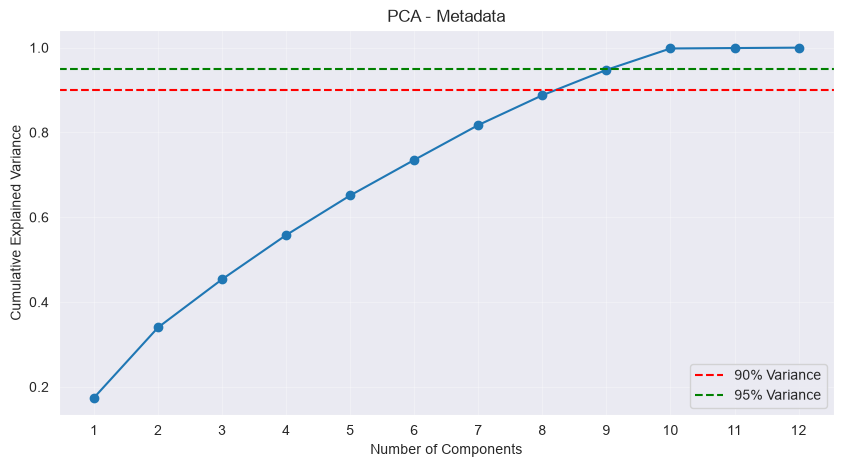

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    np.cumsum(explained_variance),
    marker="o"
)

plt.axhline(y=0.90, color="red", linestyle="--", label="90% Variance")
plt.axhline(y=0.95, color="green", linestyle="--", label="95% Variance")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Metadata")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Image Stats PCA

In [26]:
df_image_stats = df[image_stat_cols].copy()

scaler_image = StandardScaler()
X_image_scaled = scaler_image.fit_transform(df_image_stats)

pca_image = PCA()
X_image_pca = pca_image.fit_transform(X_image_scaled)

print("Original shape:", X_image_scaled.shape)
print("PCA shape:", X_image_pca.shape)

Original shape: (48053, 17)
PCA shape: (48053, 17)


In [27]:
explained_variance_image = pca_image.explained_variance_ratio_

pca_image_results = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(explained_variance_image))],
    "Explained Variance": explained_variance_image,
    "Cumulative Variance": np.cumsum(explained_variance_image)
})

display(pca_image_results)

,PC,Explained Variance,Cumulative Variance
0,PC1,0.212446,0.212446
1,PC2,0.141424,0.353870
2,PC3,0.114297,0.468167
3,PC4,0.086908,0.555075
4,PC5,0.078947,0.634021
5,PC6,0.066323,0.700344
6,PC7,0.058065,0.758409
7,PC8,0.052003,0.810412
8,PC9,0.049887,0.860299
9,PC10,0.039706,0.900005


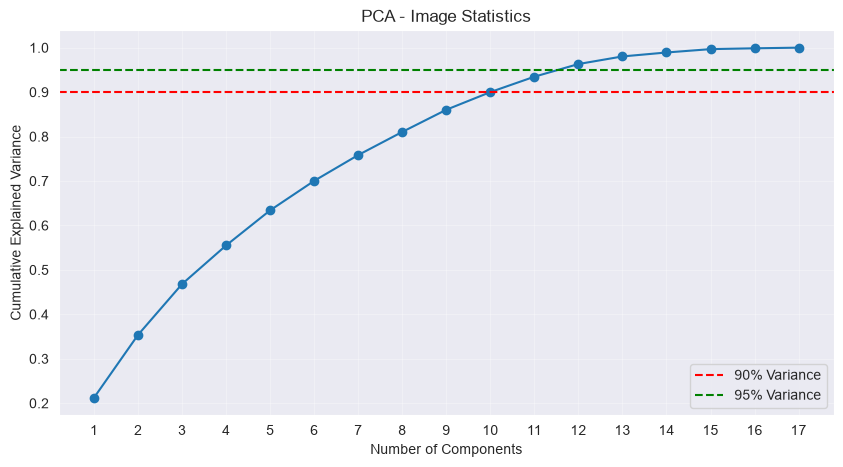

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance_image) + 1),
    np.cumsum(explained_variance_image),
    marker="o"
)

plt.axhline(y=0.90, color="red", linestyle="--", label="90% Variance")
plt.axhline(y=0.95, color="green", linestyle="--", label="95% Variance")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Image Statistics")
plt.xticks(range(1, len(explained_variance_image) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Metadata + Image Stats PCA

In [29]:
df_combined = df[meta_cols + image_stat_cols].copy()

scaler_combined = StandardScaler()
X_combined_scaled = scaler_combined.fit_transform(df_combined)

print("Original shape:", X_combined_scaled.shape)

Original shape: (48053, 29)


In [30]:
pca_combined = PCA()

X_combined_pca = pca_combined.fit_transform(X_combined_scaled)

explained_variance_combined = pca_combined.explained_variance_ratio_

pca_combined_results = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(explained_variance_combined))],
    "Explained Variance": explained_variance_combined,
    "Cumulative Variance": np.cumsum(explained_variance_combined)
})

display(pca_combined_results)

,PC,Explained Variance,Cumulative Variance
0,PC1,0.126016,0.126016
1,PC2,0.085052,0.211068
2,PC3,0.073853,0.284921
3,PC4,0.068610,0.353532
4,PC5,0.064584,0.418115
5,PC6,0.052505,0.470621
6,PC7,0.048379,0.519000
7,PC8,0.044918,0.563917
8,PC9,0.042025,0.605942
9,PC10,0.038907,0.644849


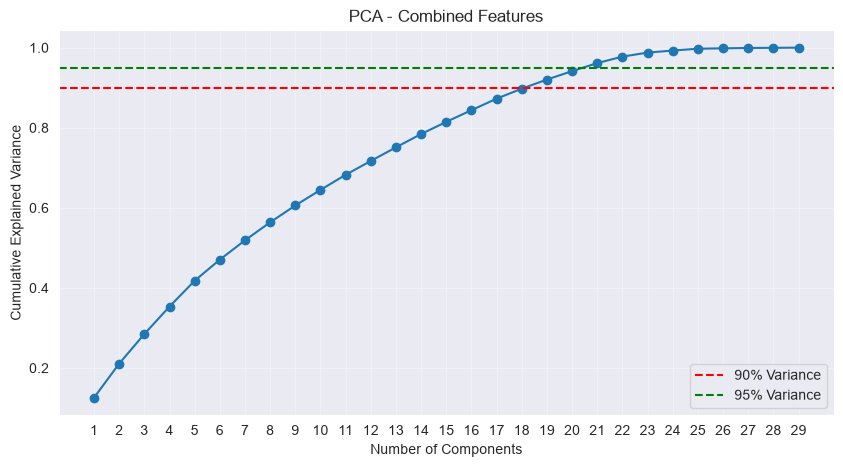

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance_combined) + 1),
    np.cumsum(explained_variance_combined),
    marker="o"
)

plt.axhline(y=0.90, color="red", linestyle="--", label="90% Variance")
plt.axhline(y=0.95, color="green", linestyle="--", label="95% Variance")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Combined Features")
plt.xticks(range(1, len(explained_variance_combined) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Metadata UMAP

In [32]:
umap_metadata = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=SEED
)

X_metadata_umap = umap_metadata.fit_transform(X_metadata_scaled)

df_umap_metadata = pd.DataFrame(
    X_metadata_umap,
    columns=["UMAP1", "UMAP2"],
    index=df.index
)

print("UMAP shape:", X_metadata_umap.shape)

C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (48053, 2)


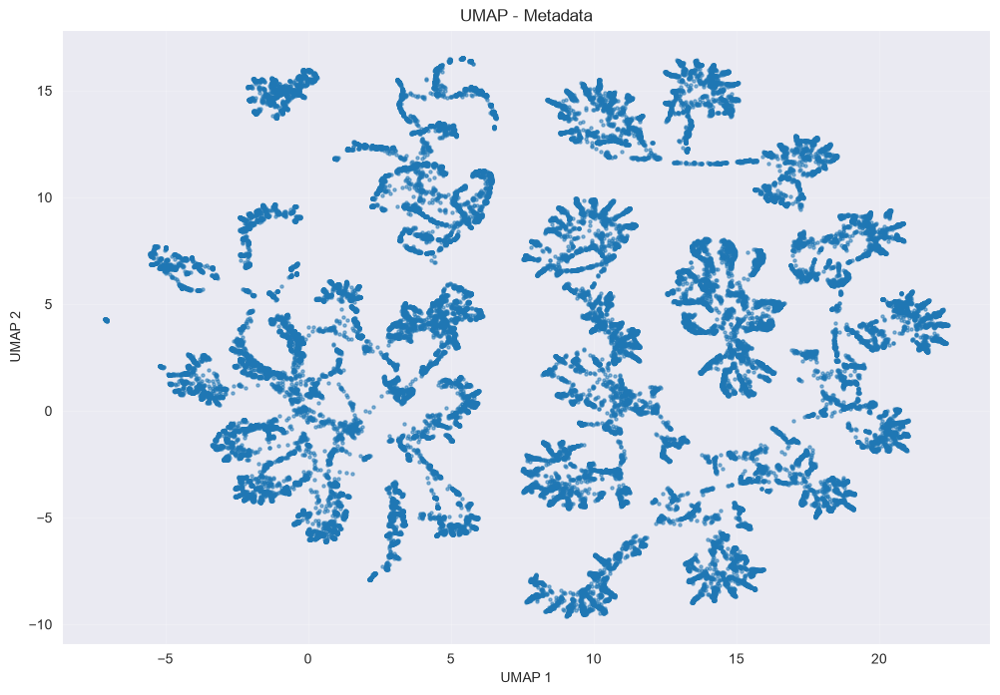

In [33]:
plt.figure(figsize=(12, 8))

plt.scatter(
    df_umap_metadata["UMAP1"],
    df_umap_metadata["UMAP2"],
    s=5,
    alpha=0.5
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP - Metadata")
plt.grid(alpha=0.2)
plt.show()

# Image Stats UMAP

In [34]:
umap_image = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=SEED
)

X_image_umap = umap_image.fit_transform(X_image_scaled)

df_umap_image = pd.DataFrame(
    X_image_umap,
    columns=["UMAP1", "UMAP2"],
    index=df.index
)

print("UMAP shape:", X_image_umap.shape)

C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (48053, 2)


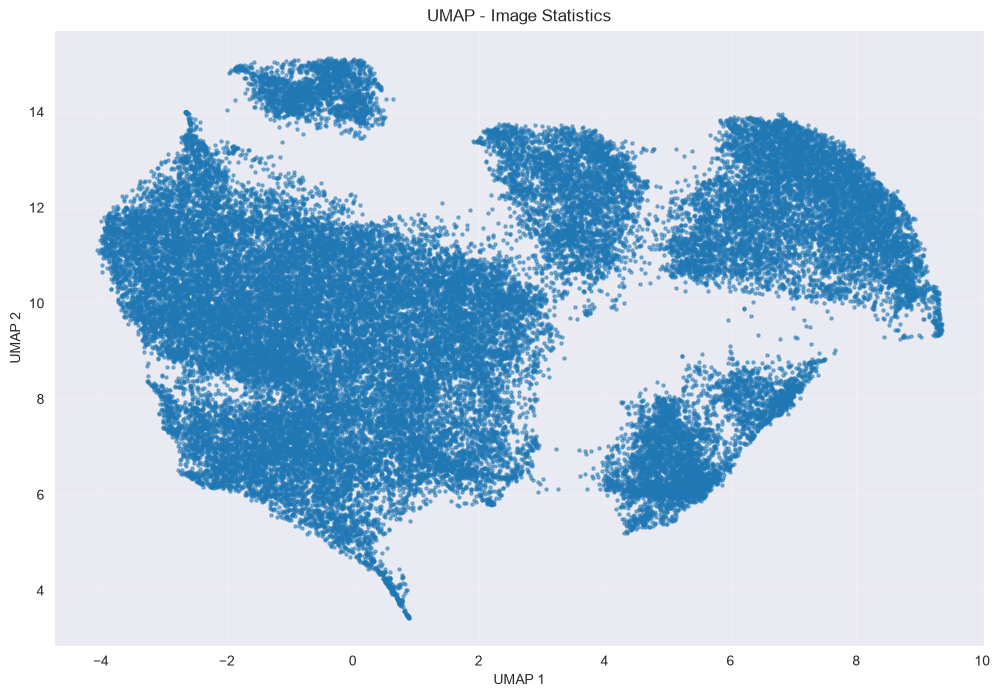

In [35]:
plt.figure(figsize=(12, 8))

plt.scatter(
    df_umap_image["UMAP1"],
    df_umap_image["UMAP2"],
    s=5,
    alpha=0.5
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP - Image Statistics")
plt.grid(alpha=0.2)
plt.show()

# Metadata + Image Stats UMAP

In [36]:
umap_combined = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=SEED
)

X_combined_umap = umap_combined.fit_transform(X_combined_scaled)

df_umap_combined = pd.DataFrame(
    X_combined_umap,
    columns=["UMAP1", "UMAP2"],
    index=df.index
)

print("UMAP shape:", X_combined_umap.shape)

C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (48053, 2)


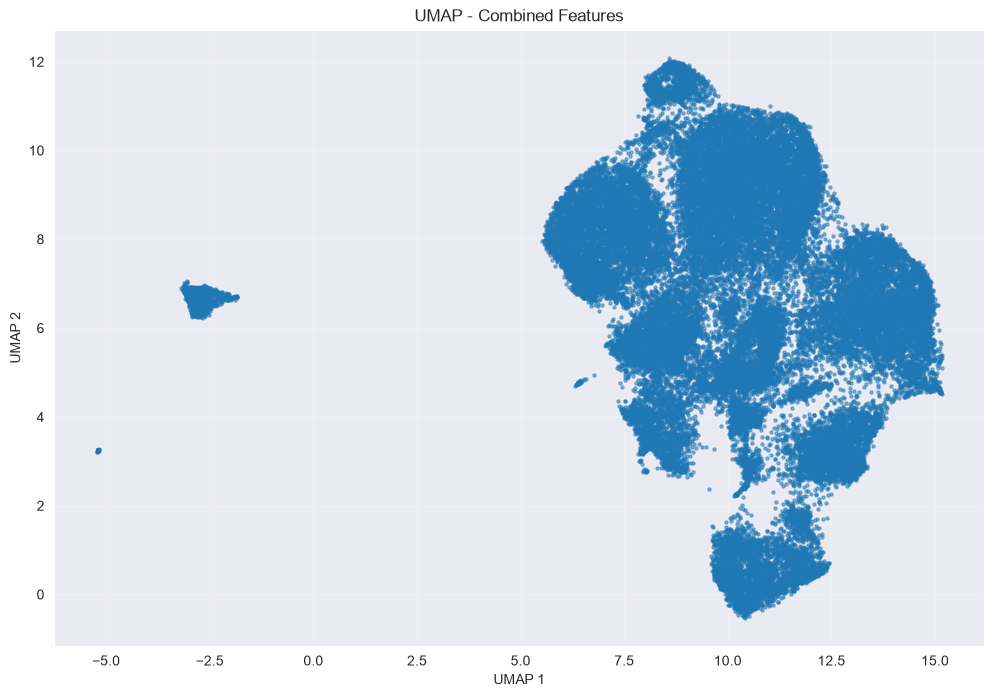

In [37]:
plt.figure(figsize=(12, 8))

plt.scatter(
    df_umap_combined["UMAP1"],
    df_umap_combined["UMAP2"],
    s=5,
    alpha=0.5
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP - Combined Features")
plt.grid(alpha=0.2)
plt.show()

# Colored UMAPS based on Year and Species

<div dir="rtl" style="text-align: right;">

## UMAP

برای بررسی ساختار داده‌ها، الگوریتم UMAP روی سه مجموعه ویژگی Metadata، Image Statistics و Combined اجرا شد. هدف، نمایش دوبعدی داده‌ها و بررسی الگوهای احتمالی بین ویژگی‌ها بود.

برای بررسی بهتر نتایج، نمودارها بر اساس گونه پرنده (`species_scientific`) و سال مشاهده (`year`) رنگ‌بندی شدند.

### نتایج

Metadata

نقاط به چندین جزیره مجزا تقسیم شدند. در نمودار مربوط به گونه‌ها، در بعضی جزیره‌ها رنگ نقاط تقریباً یکسان بود. همچنین در نمودار سال، تعدادی از جزیره‌ها بیشتر شامل مشاهدات مربوط به سال‌های قدیمی‌تر بودند.

Image Statistics

بیشتر نقاط در نواحی متراکم قرار گرفتند و رنگ گونه‌های مختلف هم‌پوشانی زیادی داشت. بنابراین، جداسازی مشخصی بین گونه‌ها بر اساس ویژگی‌های آماری فعلی تصاویر مشاهده نشد.

Combined

بیشتر نقاط در یک ساختار متراکم قرار گرفتند و یک ناحیه کوچک و جدا نیز دیده شد. در نمودار سال، مشابه Metadata، بعضی نواحی بیشتر شامل مشاهدات سال‌های قدیمی‌تر بودند.

جمع‌بندی

به نظر می‌رسد Metadata ساختارهای جزیره‌ای مشخص‌تری ایجاد می‌کند و برخی از این ساختارها با گونه و سال مشاهده ارتباط دارند. در مقابل، Image Statistics تفکیک مشخصی بین گونه‌ها نشان نداد. ترکیب دو مجموعه ویژگی نیز ساختار متفاوتی نسبت به هرکدام به‌تنهایی ایجاد کرد.


</div>

In [38]:
species_codes, species_names = pd.factorize(
    df["species_scientific"],
    sort=True
)

n_species = len(species_names)

species_colors = plt.cm.hsv(
    np.linspace(0, 1, n_species, endpoint=False)
)

species_cmap = ListedColormap(species_colors)

species_norm = BoundaryNorm(
    np.arange(-0.5, n_species + 0.5, 1),
    n_species
)

print("Number of species:", n_species)

Number of species: 100


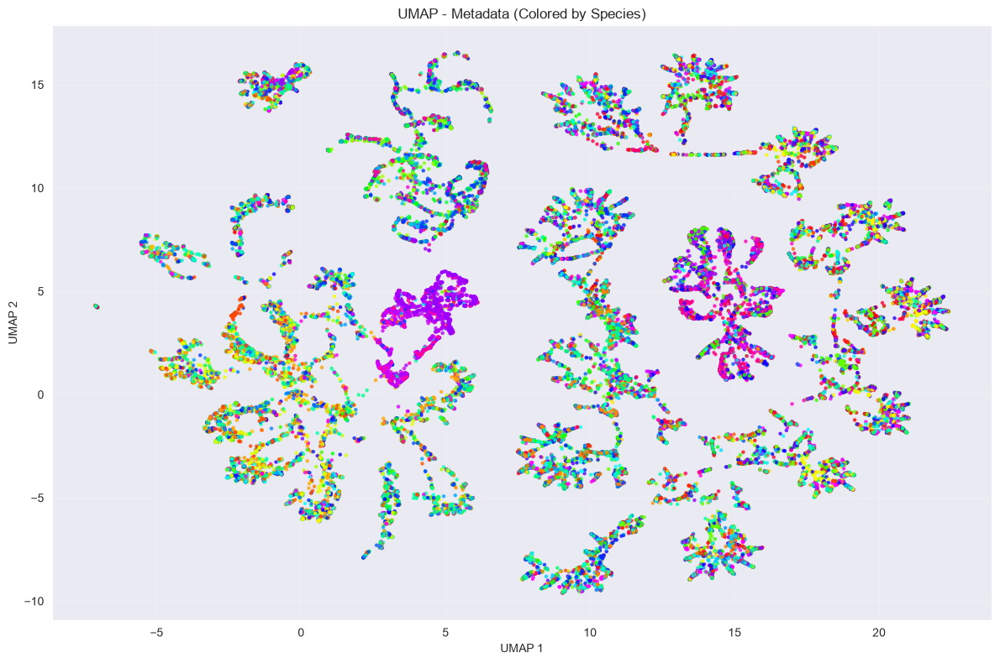

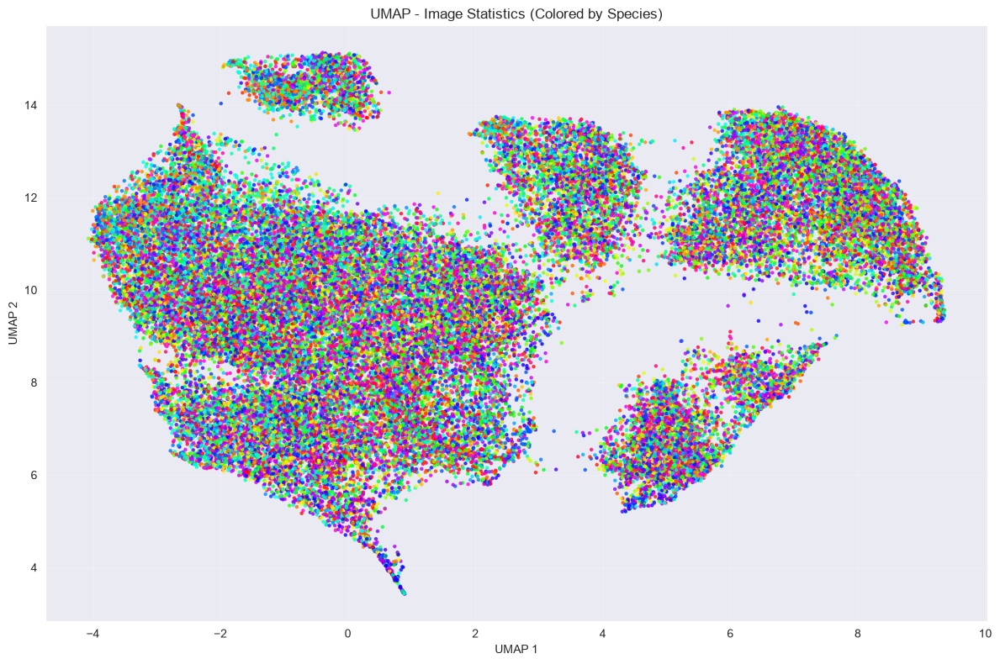

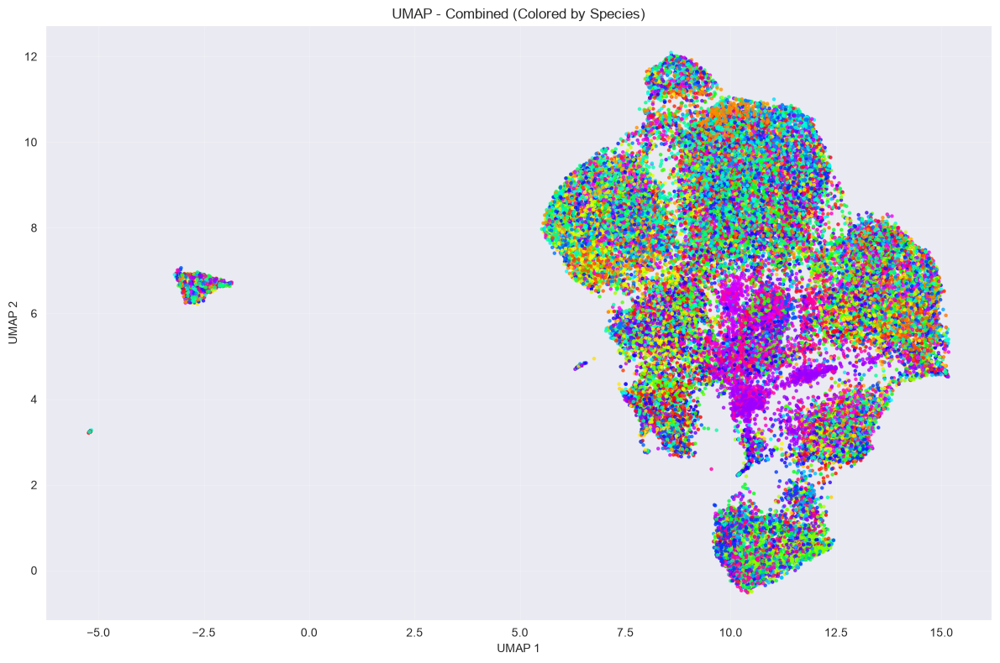

In [39]:
umap_results = {
    "Metadata": df_umap_metadata,
    "Image Statistics": df_umap_image,
    "Combined": df_umap_combined
}

for name, embedding in umap_results.items():

    plt.figure(figsize=(12, 8))

    scatter = plt.scatter(
        embedding["UMAP1"],
        embedding["UMAP2"],
        c=species_codes,
        cmap=species_cmap,
        norm=species_norm,
        s=5,
        alpha=0.7
    )

    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.title(f"UMAP - {name} (Colored by Species)")
    plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

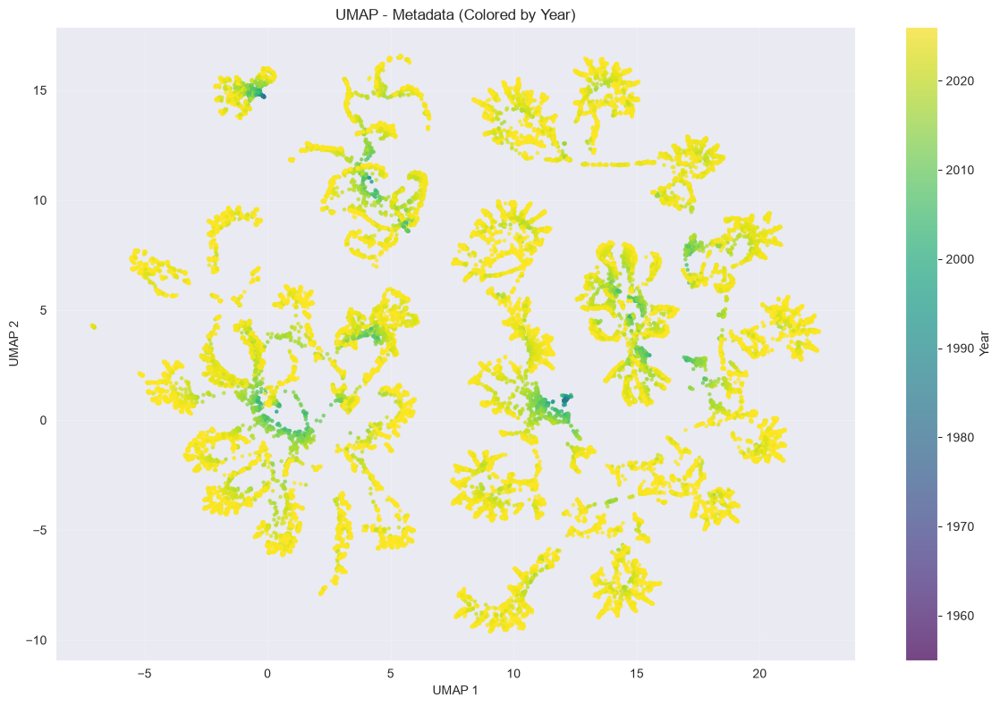

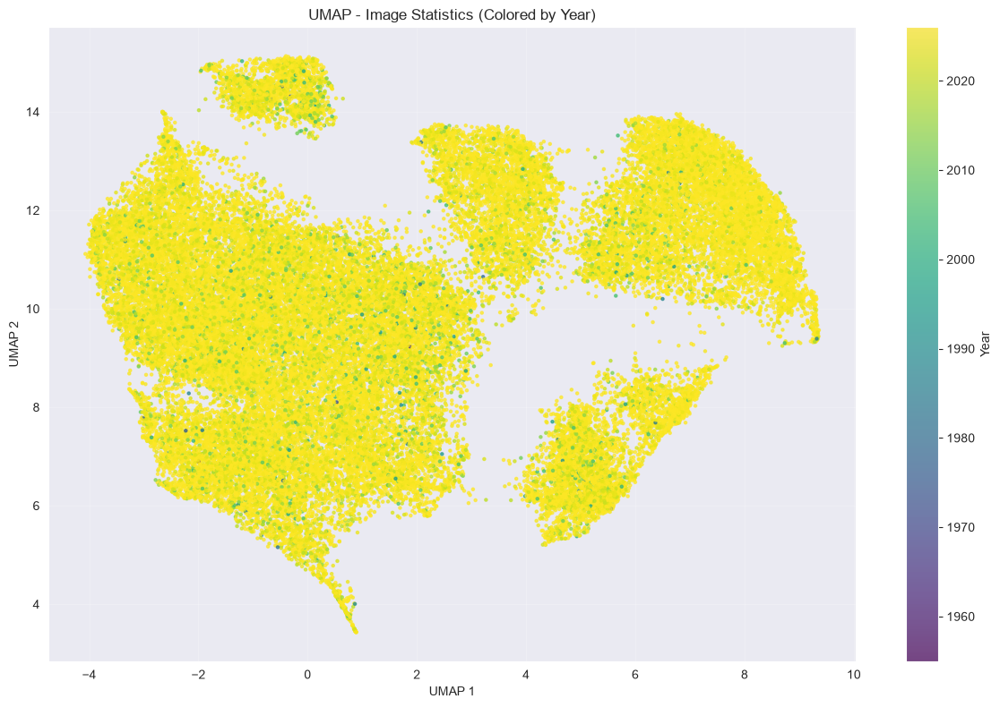

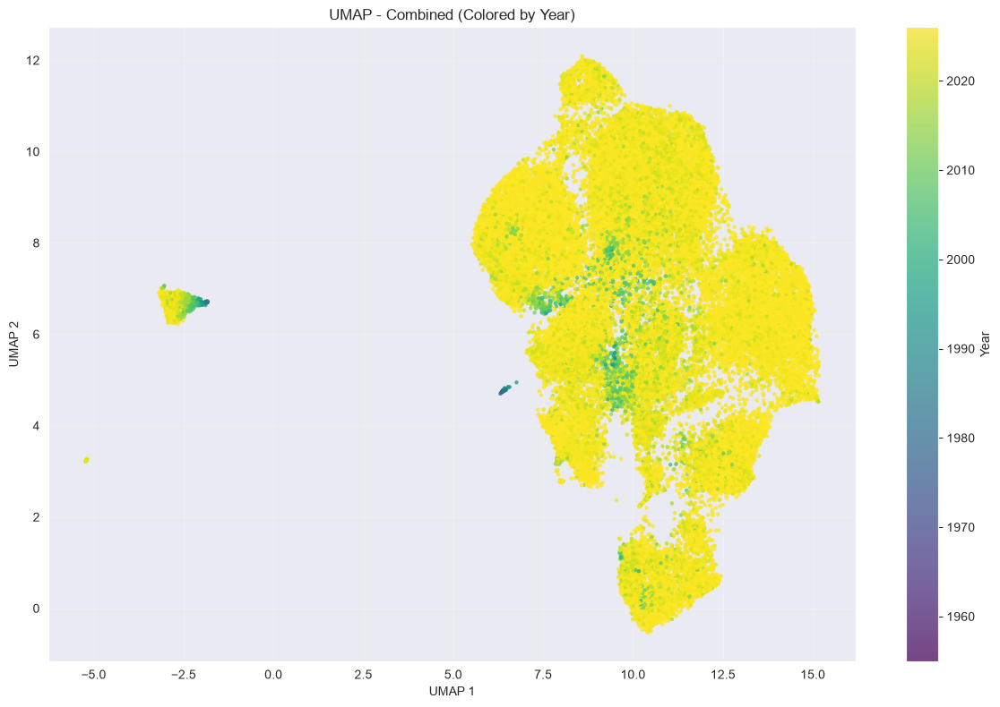

In [40]:
for name, embedding in umap_results.items():

    plt.figure(figsize=(12, 8))

    scatter = plt.scatter(
        embedding["UMAP1"],
        embedding["UMAP2"],
        c=df["year"],
        cmap="viridis",
        s=5,
        alpha=0.7
    )

    plt.colorbar(
        scatter,
        label="Year"
    )

    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.title(f"UMAP - {name} (Colored by Year)")
    plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

# K-Means

# Metadata K-Means

Testing K=2 ...
Silhouette Score: 0.1682 | DBI: 2.2429
Testing K=3 ...
Silhouette Score: 0.1612 | DBI: 1.8625
Testing K=4 ...
Silhouette Score: 0.1757 | DBI: 1.5573
Testing K=5 ...
Silhouette Score: 0.1814 | DBI: 1.5097
Testing K=6 ...
Silhouette Score: 0.1862 | DBI: 1.2749
Testing K=7 ...
Silhouette Score: 0.1622 | DBI: 1.3933
Testing K=8 ...
Silhouette Score: 0.1607 | DBI: 1.5239
Testing K=9 ...
Silhouette Score: 0.1643 | DBI: 1.4970
Testing K=10 ...
Silhouette Score: 0.1734 | DBI: 1.4182
Testing K=11 ...
Silhouette Score: 0.1770 | DBI: 1.4362
Testing K=12 ...
Silhouette Score: 0.1839 | DBI: 1.4537
Testing K=13 ...
Silhouette Score: 0.1882 | DBI: 1.4053
Testing K=14 ...
Silhouette Score: 0.1907 | DBI: 1.4129
Testing K=15 ...
Silhouette Score: 0.1928 | DBI: 1.3518
Testing K=16 ...
Silhouette Score: 0.1971 | DBI: 1.3483
Testing K=17 ...
Silhouette Score: 0.1994 | DBI: 1.3745
Testing K=18 ...
Silhouette Score: 0.1990 | DBI: 1.3547
Testing K=19 ...
Silhouette Score: 0.1871 | DBI: 1.3390


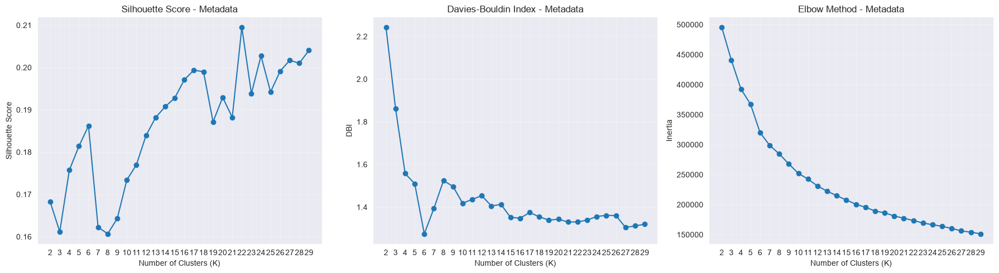

In [41]:
k_values = range(2, 30)

silhouette_scores = []
dbi_scores = []
inertias = []

for k in k_values:
    print(f"Testing K={k} ...")

    kmeans = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    labels = kmeans.fit_predict(X_metadata_scaled)

    # Silhouette Score
    score = silhouette_score(
        X_metadata_scaled,
        labels,
        sample_size=10000,
        random_state=SEED
    )

    # Davies-Bouldin Index
    dbi = davies_bouldin_score(
        X_metadata_scaled,
        labels
    )

    silhouette_scores.append(score)
    dbi_scores.append(dbi)
    inertias.append(kmeans.inertia_)

    print(f"Silhouette Score: {score:.4f} | DBI: {dbi:.4f}")

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Silhouette Score
axes[0].plot(list(k_values), silhouette_scores, marker="o")
axes[0].set_title("Silhouette Score - Metadata")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

# Davies-Bouldin Index
axes[1].plot(list(k_values), dbi_scores, marker="o")
axes[1].set_title("Davies-Bouldin Index - Metadata")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("DBI")
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)

# Elbow Method
axes[2].plot(list(k_values), inertias, marker="o")
axes[2].set_title("Elbow Method - Metadata")
axes[2].set_xlabel("Number of Clusters (K)")
axes[2].set_ylabel("Inertia")
axes[2].set_xticks(list(k_values))
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
results = {}

for k in [6, 22]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    labels = kmeans.fit_predict(X_metadata_scaled)

    results[k] = labels

    print(f"\n{'='*40}")
    print(f"K = {k}")
    print(f"{'='*40}")

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    cluster_summary = pd.DataFrame({
        "Count": cluster_sizes,
        "Percentage": (cluster_sizes / len(labels) * 100).round(2)
    })

    print("\nCluster Sizes:")
    display(cluster_summary)


K = 6

Cluster Sizes:


,Count,Percentage
0,14714,30.62
1,14033,29.20
2,78,0.16
3,4638,9.65
4,1158,2.41
5,13432,27.95



K = 22

Cluster Sizes:


,Count,Percentage
0,2203,4.58
1,1902,3.96
2,3682,7.66
3,2345,4.88
4,78,0.16
5,1082,2.25
6,2844,5.92
7,4062,8.45
8,2937,6.11
9,2241,4.66


In [43]:
idx_k6 = np.where(results[6] == 2)[0]
idx_k22 = np.where(results[22] == 4)[0]

print("K=6 cluster size:", len(idx_k6))
print("K=22 cluster size:", len(idx_k22))

print("Identical samples:", np.array_equal(
    np.sort(idx_k6),
    np.sort(idx_k22)
))

K=6 cluster size: 78
K=22 cluster size: 78
Identical samples: True


In [44]:
df_78 = df.iloc[idx_k6].copy()

print("Species distribution:")
display(
    df_78["species_scientific"]
    .value_counts()
    .to_frame("Count")
)

print("\nYear distribution:")
display(
    df_78["year"]
    .value_counts()
    .sort_index()
    .to_frame("Count")
)

print("\nMetadata statistics:")
display(df_78[meta_cols].describe().T)

Species distribution:


,Count
species_scientific,
Cygnus olor,4
Athene noctua,3
Ciconia ciconia,3
Aquila chrysaetos,3
Tyto alba,3
Ara macao,3
Trichoglossus moluccanus,3
Merops apiaster,3
Columba livia,2



Year distribution:


,Count
year,
2014,1
2017,1
2018,1
2019,1
2021,1
2022,4
2023,6
2024,7
2025,21



Metadata statistics:


,count,mean,std,min,25%,50%,75%,max
year,78.0,2024.589744,2.206460,2014.000000,2024.000000,2.025000e+03,2.026000e+03,2026.000000
month_sin,78.0,-0.001718,0.676601,-1.000000,-0.500000,-2.449294e-16,5.000000e-01,1.000000
month_cos,78.0,0.041437,0.743946,-1.000000,-0.500000,-1.836970e-16,8.660254e-01,1.000000
day_of_year_sin,78.0,-0.005241,0.699188,-0.999833,-0.661653,-7.304519e-02,7.048147e-01,0.999930
day_of_year_cos,78.0,0.032184,0.723220,-0.999166,-0.592645,-2.902072e-02,7.956672e-01,0.999991
hour_sin,78.0,-0.030014,0.681821,-1.000000,-0.707107,0.000000e+00,7.071068e-01,1.000000
hour_cos,78.0,-0.422289,0.499668,-1.000000,-0.866025,-5.000000e-01,-1.836970e-16,0.965926
has_hour,78.0,0.884615,0.321553,0.000000,1.000000,1.000000e+00,1.000000e+00,1.000000
geo_x,78.0,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000
geo_y,78.0,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000


Testing K=2 ...
Silhouette Score: 0.1704 | DBI: 2.2180
Testing K=3 ...
Silhouette Score: 0.1632 | DBI: 1.8381
Testing K=4 ...
Silhouette Score: 0.1780 | DBI: 1.5260
Testing K=5 ...
Silhouette Score: 0.1851 | DBI: 1.4794
Testing K=6 ...
Silhouette Score: 0.1610 | DBI: 1.5837
Testing K=7 ...
Silhouette Score: 0.1608 | DBI: 1.5965
Testing K=8 ...
Silhouette Score: 0.1634 | DBI: 1.6464
Testing K=9 ...
Silhouette Score: 0.1707 | DBI: 1.5371
Testing K=10 ...
Silhouette Score: 0.1746 | DBI: 1.5611
Testing K=11 ...
Silhouette Score: 0.1824 | DBI: 1.5649
Testing K=12 ...
Silhouette Score: 0.1873 | DBI: 1.4782
Testing K=13 ...
Silhouette Score: 0.1901 | DBI: 1.4568
Testing K=14 ...
Silhouette Score: 0.1968 | DBI: 1.4475
Testing K=15 ...
Silhouette Score: 0.1961 | DBI: 1.4273
Testing K=16 ...
Silhouette Score: 0.1995 | DBI: 1.4197
Testing K=17 ...
Silhouette Score: 0.2003 | DBI: 1.4092
Testing K=18 ...
Silhouette Score: 0.1991 | DBI: 1.4210
Testing K=19 ...
Silhouette Score: 0.1879 | DBI: 1.3947


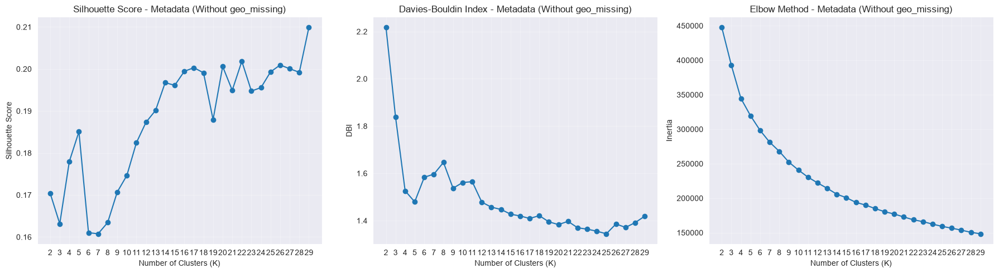

In [45]:
meta_cols_no_geo_missing = [
    col for col in meta_cols
    if col != "geo_missing"
]

scaler = StandardScaler()
X_metadata_no_geo_missing_scaled = scaler.fit_transform(
    df[meta_cols_no_geo_missing]
)

k_values = range(2, 30)

silhouette_scores = []
dbi_scores = []
inertias = []

for k in k_values:
    print(f"Testing K={k} ...")

    kmeans = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    labels = kmeans.fit_predict(X_metadata_no_geo_missing_scaled)

    # Silhouette Score
    score = silhouette_score(
        X_metadata_no_geo_missing_scaled,
        labels,
        sample_size=10000,
        random_state=SEED
    )

    # Davies-Bouldin Index
    dbi = davies_bouldin_score(
        X_metadata_no_geo_missing_scaled,
        labels
    )

    silhouette_scores.append(score)
    dbi_scores.append(dbi)
    inertias.append(kmeans.inertia_)

    print(f"Silhouette Score: {score:.4f} | DBI: {dbi:.4f}")

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Silhouette Score
axes[0].plot(list(k_values), silhouette_scores, marker="o")
axes[0].set_title("Silhouette Score - Metadata (Without geo_missing)")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

# Davies-Bouldin Index
axes[1].plot(list(k_values), dbi_scores, marker="o")
axes[1].set_title("Davies-Bouldin Index - Metadata (Without geo_missing)")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("DBI")
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)

# Elbow Method
axes[2].plot(list(k_values), inertias, marker="o")
axes[2].set_title("Elbow Method - Metadata (Without geo_missing)")
axes[2].set_xlabel("Number of Clusters (K)")
axes[2].set_ylabel("Inertia")
axes[2].set_xticks(list(k_values))
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
for k in [5, 22]:
    kmeans = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    df[f"metadata_cluster_{k}"] = kmeans.fit_predict(
        X_metadata_no_geo_missing_scaled
    )

    counts = df[f"metadata_cluster_{k}"].value_counts().sort_index()

    result = pd.DataFrame({
        "Count": counts,
        "Percentage": (counts / len(df) * 100).round(2)
    })

    print(f"\nDistribution for K={k}")
    print(result)


Distribution for K=5
                    Count  Percentage
metadata_cluster_5                   
0                   14057       29.25
1                    1167        2.43
2                    4639        9.65
3                   13455       28.00
4                   14735       30.66

Distribution for K=22
                     Count  Percentage
metadata_cluster_22                   
0                     1236        2.57
1                     3860        8.03
2                     2381        4.95
3                     2096        4.36
4                     3889        8.09
5                     2123        4.42
6                     1091        2.27
7                     2795        5.82
8                     2199        4.58
9                     1910        3.97
10                    2746        5.71
11                    2673        5.56
12                    1602        3.33
13                    1476        3.07
14                    3591        7.47
15                    2830

In [47]:
for k in [5, 22]:
    print(f"\nMetadata Feature Means - K={k}")

    cluster_means = df.groupby(
        f"metadata_cluster_{k}"
    )[meta_cols_no_geo_missing].mean()

    print(cluster_means.round(3))


Metadata Feature Means - K=5
                        year  month_sin  month_cos  day_of_year_sin  day_of_year_cos  hour_sin  hour_cos  has_hour  geo_x  geo_y  geo_z
metadata_cluster_5                                                                                                                     
0                   2024.750     -0.798     -0.251           -0.713           -0.417    -0.083    -0.552       1.0  0.364 -0.082  0.526
1                   2019.997      0.001     -0.036            0.017           -0.032     0.000     0.000       0.0  0.306  0.034  0.342
2                   2024.296     -0.050     -0.059           -0.035           -0.060    -0.079    -0.594       1.0 -0.667  0.449 -0.515
3                   2023.692      0.249      0.792            0.071            0.823    -0.077    -0.644       1.0  0.309 -0.074  0.357
4                   2024.689      0.560     -0.631            0.689           -0.485    -0.125    -0.535       1.0  0.340 -0.084  0.570

Metadata Feature 

In [48]:
for k in [5, 22]:
    top_species = (
        df.groupby([f"metadata_cluster_{k}", "species_scientific"])
        .size()
        .reset_index(name="count")
        .sort_values(
            [f"metadata_cluster_{k}", "count"],
            ascending=[True, False]
        )
        .groupby(f"metadata_cluster_{k}")
        .head(5)
    )

    print(f"\nTop 5 Species per Cluster (K={k})")
    print(top_species.to_string(index=False))


Top 5 Species per Cluster (K=5)
 metadata_cluster_5       species_scientific  count
                  0           Sterna hirundo    262
                  0           Rhea americana    249
                  0          Merops apiaster    246
                  0              Gyps fulvus    239
                  0              Gavia immer    234
                  1          Ramphastos toco     34
                  1          Aythya fuligula     30
                  1 Dromaius novaehollandiae     26
                  1        Tockus leucomelas     26
                  1          Scopus umbretta     25
                  2      Platycercus eximius    487
                  2         Cacatua galerita    486
                  2          Malurus cyaneus    483
                  2 Trichoglossus moluccanus    480
                  2      Casuarius casuarius    467
                  3         Pygoscelis papua    410
                  3       Pygoscelis adeliae    362
                  3      Bombyc

In [49]:
from sklearn.metrics import (
    homogeneity_score,
    completeness_score,
    v_measure_score,
    adjusted_rand_score
)

y_true = df["species_scientific"]

for k in [5, 22]:
    y_pred = df[f"metadata_cluster_{k}"]

    print(f"\nK={k}")
    print("Homogeneity:", homogeneity_score(y_true, y_pred))
    print("Completeness:", completeness_score(y_true, y_pred))
    print("V-measure:", v_measure_score(y_true, y_pred))
    print("ARI:", adjusted_rand_score(y_true, y_pred))


K=5
Homogeneity: 0.06634088424390722
Completeness: 0.21906774876807455
V-measure: 0.10184098504116422
ARI: 0.008985232845335898

K=22
Homogeneity: 0.17960598034288477
Completeness: 0.27646680267736706
V-measure: 0.21775073179460686
ARI: 0.03366311840381974


<div dir="rtl" style="text-align: right;">
خوشه‌بندی بر اساس ویژگی‌های Metadata

در این آزمایش، خوشه‌بندی بدون نظارت با الگوریتم K-Means و بر اساس ویژگی‌های زمانی و جغرافیایی تصاویر انجام شد. ویژگی‌های مورد استفاده شامل سال، ماه، روز سال، ساعت ثبت تصویر و مختصات جغرافیایی بودند. پیش از خوشه‌بندی، ویژگی‌ها با استفاده از StandardScaler استانداردسازی شدند.

دو مقدار متفاوت برای تعداد خوشه‌ها، یعنی K=5 و K=22، بررسی شدند. برای ارزیابی ارتباط خوشه‌ها با گونه‌های واقعی، چهار معیار محاسبه شد:

| معیار | K=5 | K=22 |
|---|---:|---:|
| Homogeneity | 0.0663 | 0.1796 |
| Completeness | 0.2191 | 0.2765 |
| V-measure | 0.1018 | 0.2178 |
| ARI | 0.0090 | 0.0337 |

با افزایش تعداد خوشه‌ها، مقادیر تمام معیارها بهبود یافتند؛ بااین‌حال، امتیازها همچنان پایین بودند. این نتایج نشان می‌دهند که ویژگی‌های زمانی و جغرافیایی به‌تنهایی توانایی محدودی در تفکیک گونه‌های مختلف پرندگان دارند.

در مجموع، خوشه‌بندی انجام‌شده بیشتر ساختارهای زمانی و جغرافیایی موجود در داده‌ها را شناسایی کرده است و تطابق چندانی با دسته‌بندی واقعی گونه‌ها ندارد.
</div>


========== SEED = 42 ==========
Testing K=2 ...
Silhouette: 0.1704 | DBI: 2.2180
Testing K=3 ...
Silhouette: 0.1632 | DBI: 1.8381
Testing K=4 ...
Silhouette: 0.1780 | DBI: 1.5260
Testing K=5 ...
Silhouette: 0.1851 | DBI: 1.4794
Testing K=6 ...
Silhouette: 0.1610 | DBI: 1.5837
Testing K=7 ...
Silhouette: 0.1608 | DBI: 1.5965
Testing K=8 ...
Silhouette: 0.1634 | DBI: 1.6464
Testing K=9 ...
Silhouette: 0.1707 | DBI: 1.5371
Testing K=10 ...
Silhouette: 0.1746 | DBI: 1.5611
Testing K=11 ...
Silhouette: 0.1824 | DBI: 1.5649
Testing K=12 ...
Silhouette: 0.1873 | DBI: 1.4782
Testing K=13 ...
Silhouette: 0.1901 | DBI: 1.4568
Testing K=14 ...
Silhouette: 0.1968 | DBI: 1.4475
Testing K=15 ...
Silhouette: 0.1961 | DBI: 1.4273
Testing K=16 ...
Silhouette: 0.1995 | DBI: 1.4197
Testing K=17 ...
Silhouette: 0.2003 | DBI: 1.4092
Testing K=18 ...
Silhouette: 0.1991 | DBI: 1.4210
Testing K=19 ...
Silhouette: 0.1879 | DBI: 1.3947
Testing K=20 ...
Silhouette: 0.2006 | DBI: 1.3832
Testing K=21 ...
Silhouet

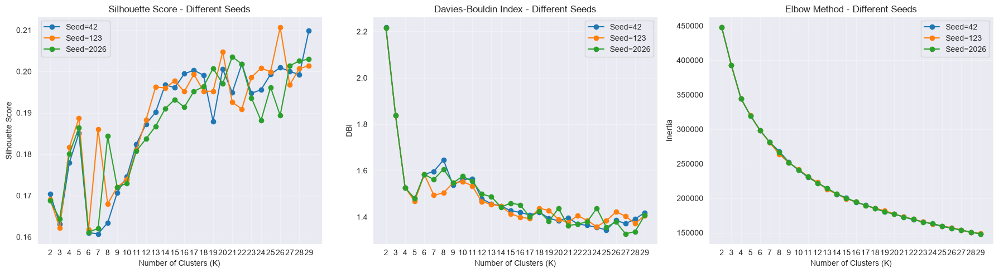

In [50]:
k_values = range(2, 30)

all_results = {}

for seed in RANDOM_SEEDS:
    print(f"\n========== SEED = {seed} ==========")

    silhouette_scores = []
    dbi_scores = []
    inertias = []

    for k in k_values:
        print(f"Testing K={k} ...")

        kmeans = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10
        )

        labels = kmeans.fit_predict(
            X_metadata_no_geo_missing_scaled
        )

        score = silhouette_score(
            X_metadata_no_geo_missing_scaled,
            labels,
            sample_size=10000,
            random_state=seed
        )

        dbi = davies_bouldin_score(
            X_metadata_no_geo_missing_scaled,
            labels
        )

        silhouette_scores.append(score)
        dbi_scores.append(dbi)
        inertias.append(kmeans.inertia_)

        print(f"Silhouette: {score:.4f} | DBI: {dbi:.4f}")

    all_results[seed] = {
        "silhouette": silhouette_scores,
        "dbi": dbi_scores,
        "inertia": inertias
    }


# Plot results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for seed in RANDOM_SEEDS:
    axes[0].plot(
        list(k_values),
        all_results[seed]["silhouette"],
        marker="o",
        label=f"Seed={seed}"
    )

    axes[1].plot(
        list(k_values),
        all_results[seed]["dbi"],
        marker="o",
        label=f"Seed={seed}"
    )

    axes[2].plot(
        list(k_values),
        all_results[seed]["inertia"],
        marker="o",
        label=f"Seed={seed}"
    )

axes[0].set_title("Silhouette Score - Different Seeds")
axes[0].set_ylabel("Silhouette Score")

axes[1].set_title("Davies-Bouldin Index - Different Seeds")
axes[1].set_ylabel("DBI")

axes[2].set_title("Elbow Method - Different Seeds")
axes[2].set_ylabel("Inertia")

for ax in axes:
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_xticks(list(k_values))
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
بررسی پایداری خوشه‌بندی Metadata نسبت به تغییر Seed

به‌منظور بررسی پایداری نتایج خوشه‌بندی، الگوریتم K-Means با سه مقدار متفاوت برای `random_state` شامل 42، 123 و 2026 اجرا شد. در این آزمایش، مقادیر K از 2 تا 29 بررسی و سه معیار Silhouette Score، Davies-Bouldin Index و Inertia مقایسه شدند.

نتایج نشان دادند که منحنی‌های مربوط به هر سه Seed، به‌ویژه در معیارهای Davies-Bouldin و Inertia، شباهت زیادی به یکدیگر دارند. اگرچه در برخی مقادیر K، به‌خصوص در Silhouette Score، اختلاف‌هایی مشاهده شد، روند کلی معیارها تقریباً ثابت باقی ماند.

در مجموع، نتایج نشان می‌دهند که ساختار کلی خوشه‌بندی Metadata نسبت به تغییر Seed پایداری مناسبی دارد و به مقداردهی اولیه الگوریتم وابستگی زیادی نشان نمی‌دهد.
</div>

# PCA on resnet50_embeddings

In [51]:
df_embedding = pd.read_csv("../inat_birds/resnet50_embedding.csv")

embedding_cols = [col for col in df_embedding.columns if col.startswith("embedding_")]

X = df_embedding[embedding_cols].to_numpy(dtype=np.float32)

print("Shape:", X.shape)

Shape: (48053, 2048)


In [52]:
print("Mean:", X.mean())
print("Std:", X.std())
print("Min:", X.min())
print("Max:", X.max())

Mean: 0.051182933
Std: 0.19732842
Min: 0.0
Max: 19.661337


In [53]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

for n in [2, 5, 10, 20, 50, 100, 200, 500, 1000, 2048]:
    print(f"{n} components: {cumulative_variance[n-1]:.4%}")

2 components: 8.2297%
5 components: 12.6185%
10 components: 16.7643%
20 components: 22.1948%
50 components: 31.7588%
100 components: 40.9398%
200 components: 51.6531%
500 components: 68.8590%
1000 components: 84.6352%
2048 components: 100.0000%


In [54]:
pca = PCA()
pca.fit(X)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

for n in [2, 5, 10, 20, 50, 100, 200, 300, 400, 500, 1000, 2048]:
    print(f"{n} components: {cumulative_variance[n-1]:.4%}")

2 components: 12.0050%
5 components: 22.1215%
10 components: 31.8909%
20 components: 42.8867%
50 components: 59.8605%
100 components: 71.9039%
200 components: 82.0307%
300 components: 87.0967%
400 components: 90.1929%
500 components: 92.3105%
1000 components: 97.3286%
2048 components: 100.0002%


<div dir="rtl" style="text-align: right;">
که با توجه به نتایج فهمیدیم scale کردن کار خوبی نیست اینجا برای pca. پس بدون scale کردن pca می‌گیریم و n_components = 400 رو انتخاب می‌کنیم که 90% واریانس رو توضیح می‌ده.
</div>

In [55]:
pca = PCA(n_components=400)

X_pca = pca.fit_transform(X)

print("PCA shape:", X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

PCA shape: (48053, 400)
Explained variance: 0.9008512


# UMAP on X_pca

In [56]:
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=SEED
)

X_umap = reducer.fit_transform(X_pca)

print("UMAP shape:", X_umap.shape)

C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\Yas\pytorch-gpu\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (48053, 2)


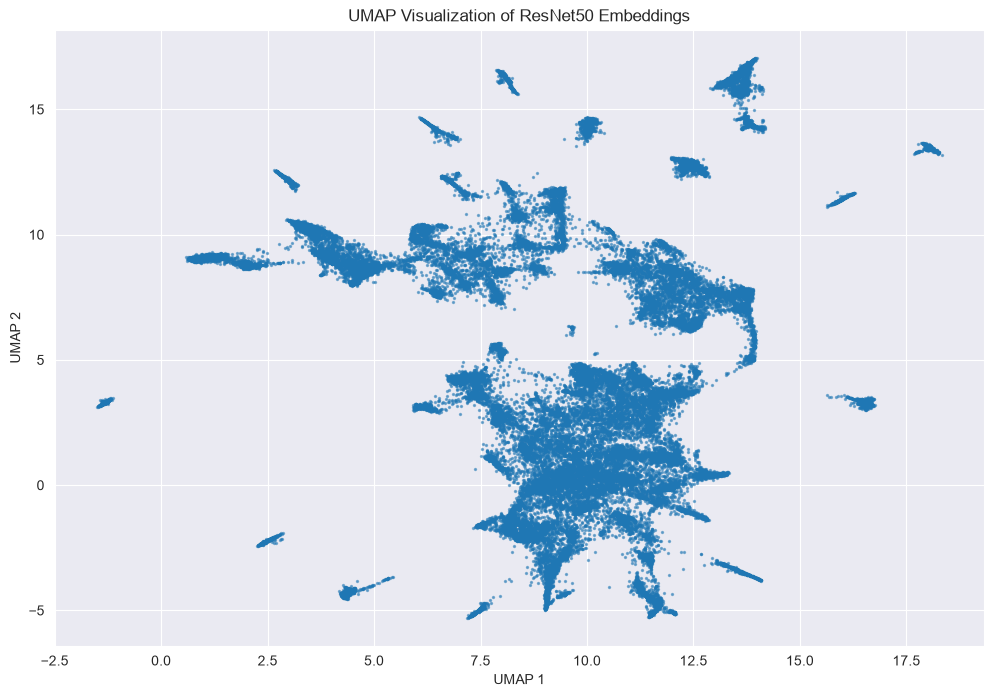

In [57]:
plt.figure(figsize=(12, 8))

plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    s=2,
    alpha=0.5
)

plt.title("UMAP Visualization of ResNet50 Embeddings")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.show()

# coloring the UMAP based on species

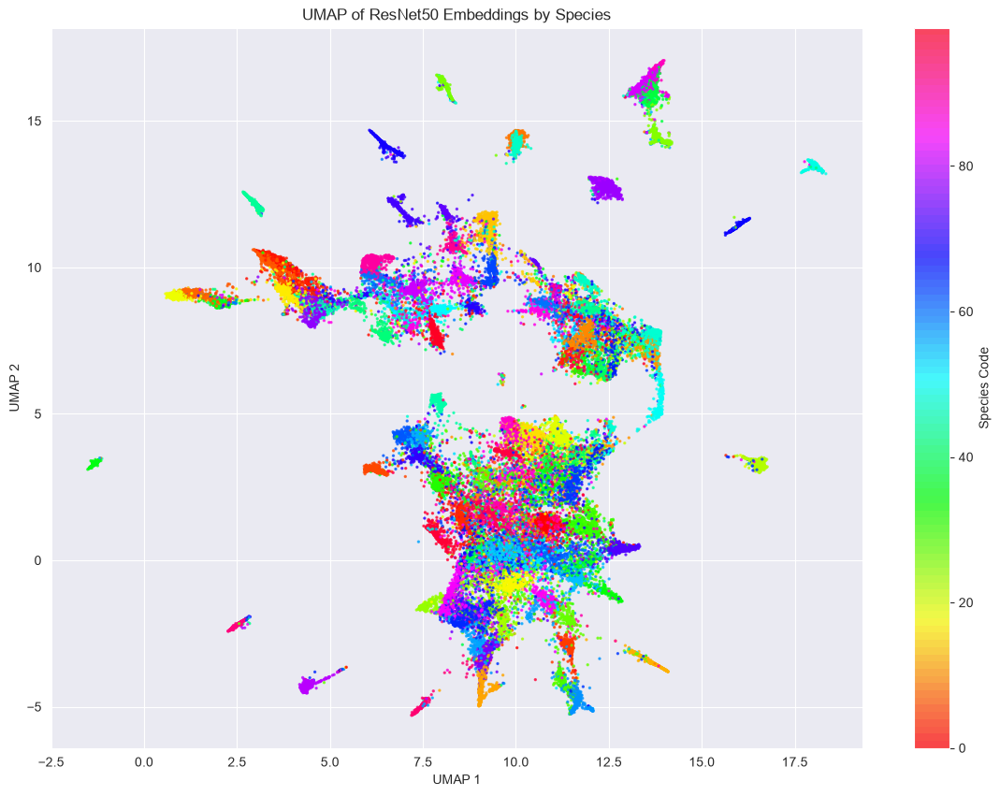

In [58]:
species_codes = df_embedding["species_scientific"].astype("category").cat.codes

plt.figure(figsize=(14, 10))

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=species_codes,
    cmap=species_cmap,
    s=2,
    alpha=0.7
)

plt.title("UMAP of ResNet50 Embeddings by Species")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.colorbar(scatter, label="Species Code")
plt.show()

<div dir="rtl" style="text-align: right;">
نتایج نشان می‌دهد در UMAP, گونه‌ها خیلی خوب از هم جدا شده‌اند.
</div>

In [59]:
geo_mask = df["latitude"].notna() & df["longitude"].notna()

X_umap_geo = X_umap[geo_mask.to_numpy()]

geo_df = df_embedding.loc[geo_mask].copy()

print("Valid samples:", len(geo_df))
print("UMAP shape:", X_umap_geo.shape)

Valid samples: 47975
UMAP shape: (47975, 2)


In [60]:
df["image_path"] = "../inat_birds\\" + df["image_path"]

In [61]:
merged_df = df_embedding.merge(
    df[["image_path", "latitude", "longitude"]],
    on="image_path",
    how="inner",
    validate="one_to_one"
)

print("Merged shape:", merged_df.shape)
print("Missing coordinates:")
print(merged_df[["latitude", "longitude"]].isna().sum())

Merged shape: (48053, 2052)
Missing coordinates:
latitude     78
longitude    78
dtype: int64


In [62]:
merged_df = merged_df.reset_index(drop=True)

geo_mask = (
    merged_df["latitude"].notna() &
    merged_df["longitude"].notna()
)

geo_df = merged_df.loc[geo_mask].copy()

X_umap_geo = X_umap[geo_mask.to_numpy()]

print("Images with coordinates:", len(geo_df))
print("UMAP shape:", X_umap_geo.shape)

Images with coordinates: 47975
UMAP shape: (47975, 2)


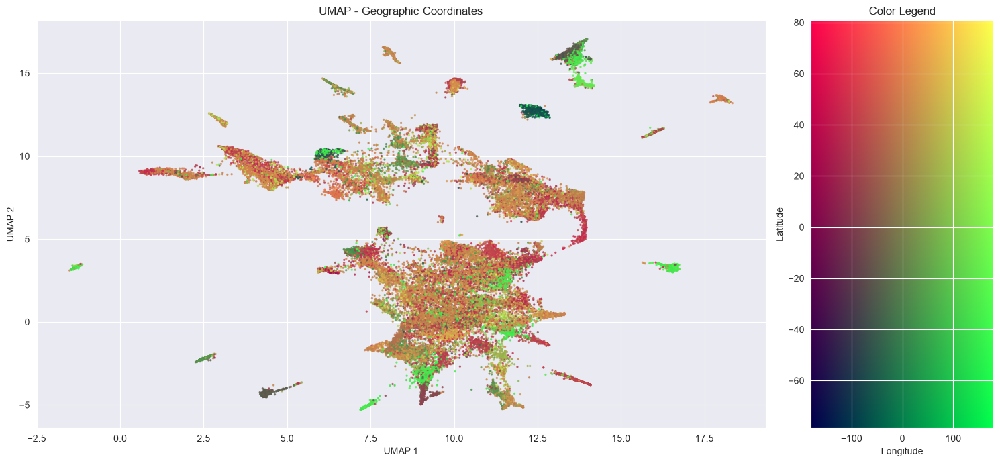

In [63]:
lat = geo_df["latitude"].to_numpy()
lon = geo_df["longitude"].to_numpy()

lat_norm = (lat - lat.min()) / (lat.max() - lat.min())
lon_norm = (lon - lon.min()) / (lon.max() - lon.min())

colors = np.column_stack([
    lat_norm,
    lon_norm,
    np.full(len(lat), 0.3)
])

fig, ax = plt.subplots(1, 2, figsize=(15, 7),
                       gridspec_kw={"width_ratios": [4, 1]})

# UMAP
ax[0].scatter(
    X_umap_geo[:, 0],
    X_umap_geo[:, 1],
    c=colors,
    s=2,
    alpha=0.7
)

ax[0].set_title("UMAP - Geographic Coordinates")
ax[0].set_xlabel("UMAP 1")
ax[0].set_ylabel("UMAP 2")

# 2D color legend
resolution = 100
lon_grid, lat_grid = np.meshgrid(
    np.linspace(0, 1, resolution),
    np.linspace(0, 1, resolution)
)

legend_colors = np.stack([
    lat_grid,
    lon_grid,
    np.full_like(lat_grid, 0.3)
], axis=-1)

ax[1].imshow(
    legend_colors,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    aspect="auto"
)

ax[1].set_title("Color Legend")
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
نمودار نشان می‌دهد که تصاویر متعلق به مناطق جغرافیایی متفاوت، اغلب در بخش‌های مشترکی از فضای UMAP قرار گرفته‌اند. بااین‌حال، برخی خوشه‌های جداافتاده مختصات جغرافیایی نسبتاً مشابهی دارند که می‌تواند نشان‌دهنده ارتباط احتمالی میان ویژگی‌های بصری و موقعیت جغرافیایی باشد. در مجموع، به نظر می‌رسد موقعیت جغرافیایی به‌تنهایی عامل تعیین‌کننده ساختار فضای تعبیه‌شده نیست.
</div>

In [64]:
from sklearn.cluster import MiniBatchKMeans

k_values = [5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100, 110 ]

silhouette_scores = []
dbi_scores = []

for k in k_values:
    kmeans = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=3
    )

    labels = kmeans.fit_predict(X_pca)

    # Silhouette on a random sample
    sil = silhouette_score(
        X_pca,
        labels,
        sample_size=5000,
        random_state=42
    )

    # DBI on the same random sample
    dbi = davies_bouldin_score(
        X_pca,
        labels
    )

    silhouette_scores.append(sil)
    dbi_scores.append(dbi)

    print(f"K={k} | Silhouette={sil:.4f} | DBI={dbi:.4f}")

K=5 | Silhouette=0.0593 | DBI=3.5659
K=10 | Silhouette=0.0567 | DBI=3.2814
K=15 | Silhouette=0.0664 | DBI=2.9784
K=20 | Silhouette=0.0732 | DBI=2.9448
K=25 | Silhouette=0.0736 | DBI=2.9289
K=30 | Silhouette=0.0844 | DBI=2.8237
K=40 | Silhouette=0.0870 | DBI=2.7746
K=50 | Silhouette=0.1050 | DBI=2.6222
K=60 | Silhouette=0.1096 | DBI=2.7325
K=70 | Silhouette=0.0927 | DBI=2.8005
K=80 | Silhouette=0.1012 | DBI=2.6972
K=90 | Silhouette=0.1003 | DBI=2.7942
K=100 | Silhouette=0.0953 | DBI=2.8607
K=110 | Silhouette=0.0900 | DBI=2.9244


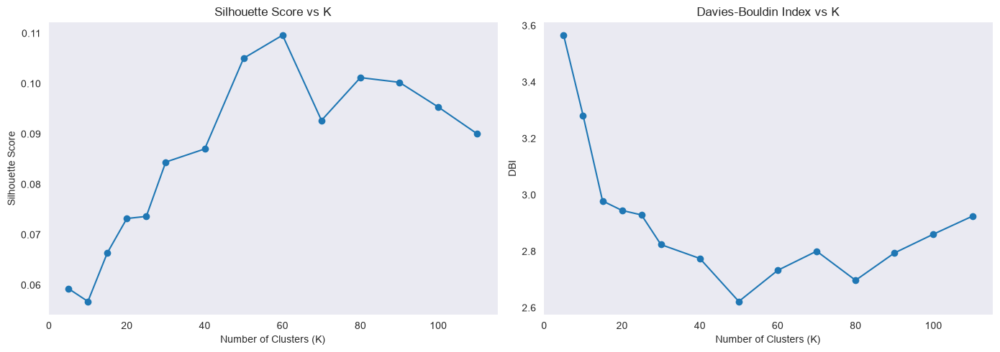

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, silhouette_scores, marker="o")
axes[0].set_title("Silhouette Score vs K")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Silhouette Score")
axes[0].grid()

axes[1].plot(k_values, dbi_scores, marker="o")
axes[1].set_title("Davies-Bouldin Index vs K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("DBI")
axes[1].grid()

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
که نمودار‌ها نشان می‌دهند k=50 می‌تواند گزینه‌ی خوبی باشد.
</div>

In [66]:
kmeans_final = MiniBatchKMeans(
    n_clusters=50,
    random_state=SEED,
    batch_size=2048,
    n_init=5
)

clusters = kmeans_final.fit_predict(X_pca)

merged_df["cluster"] = clusters

print(merged_df["cluster"].value_counts().sort_index())

cluster
0      926
1     1769
2     1452
3     1249
4      521
5     1542
6      879
7     1808
8      485
9      682
10     655
11    1075
12     578
13    1156
14    1306
15    1225
16     680
17     922
18    1092
19    1292
20     437
21     781
22    1019
23    1313
24     858
25     798
26    1569
27     555
28     783
29    1066
30     811
31     407
32    1333
33    1283
34     407
35     464
36    1541
37     830
38     952
39    1253
40     535
41    1067
42     493
43     777
44     859
45     357
46    1504
47     497
48    1755
49     455
Name: count, dtype: int64


In [67]:
top_species = (
    merged_df.groupby(["cluster", "species_scientific"])
    .size()
    .reset_index(name="count")
    .sort_values(["cluster", "count"], ascending=[True, False])
    .groupby("cluster")
    .head(5)
    .reset_index(drop=True)
)

print(top_species)

     cluster        species_scientific  count
0          0               Upupa epops    265
1          0             Columba livia     64
2          0   Melopsittacus undulatus     45
3          0     Streptopelia decaocto     34
4          0            Motacilla alba     31
5          1         Falco tinnunculus    333
6          1         Buteo jamaicensis    288
7          1          Falco peregrinus    268
8          1           Bubo scandiacus    178
9          1         Pandion haliaetus    176
10         2     Himantopus himantopus    395
11         2    Recurvirostra avosetta    349
12         2         Vanellus vanellus    151
13         2            Sterna hirundo    125
14         2           Scopus umbretta    119
15         3          Struthio camelus    474
16         3            Rhea americana    438
17         3  Dromaius novaehollandiae    325
18         3       Casuarius casuarius      6
19         3               Anser anser      1
20         4          Cacatua gale

In [68]:
from sklearn.metrics import (
    homogeneity_score,
    completeness_score,
    v_measure_score,
    adjusted_rand_score
)

y_true = merged_df["species_scientific"]
y_pred = merged_df["cluster"]

print("Homogeneity:", homogeneity_score(y_true, y_pred))
print("Completeness:", completeness_score(y_true, y_pred))
print("V-measure:", v_measure_score(y_true, y_pred))
print("ARI:", adjusted_rand_score(y_true, y_pred))

Homogeneity: 0.5644382615131855
Completeness: 0.6796544967944133
V-measure: 0.6167112541063562
ARI: 0.2912489656030371


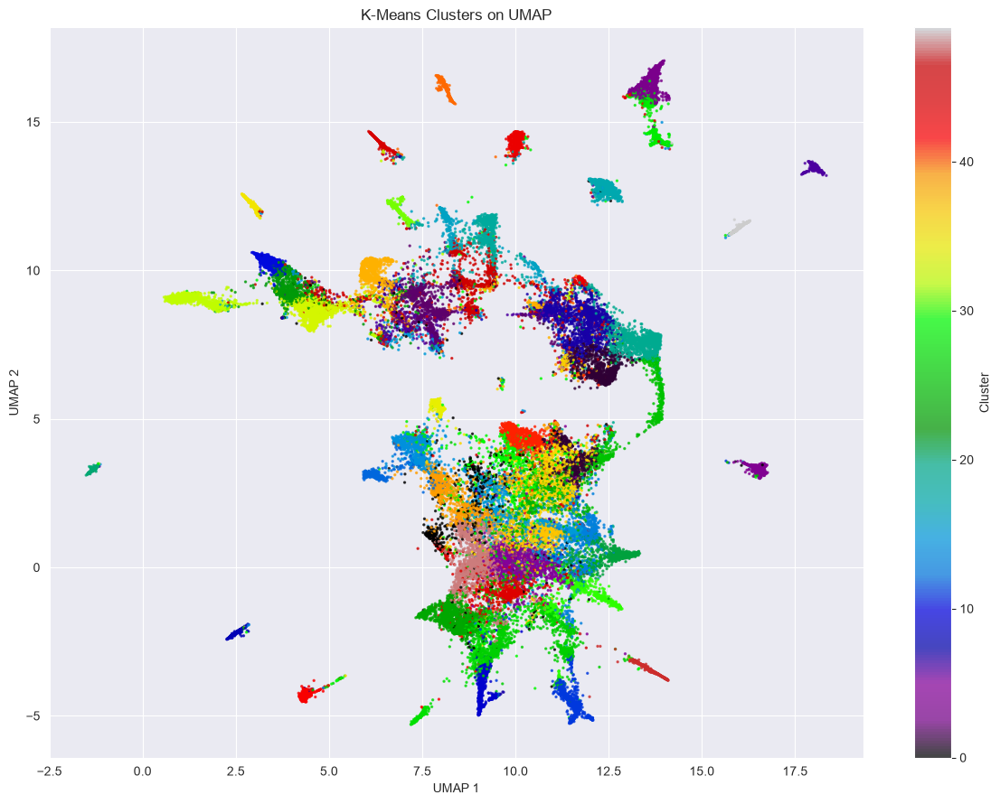

In [69]:
plt.figure(figsize=(12, 9))

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=merged_df["cluster"],
    cmap="nipy_spectral",
    s=2,
    alpha=0.7
)

plt.title("K-Means Clusters on UMAP")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
خوشه‌بندی بدون نظارت تصاویر پرندگان

برای بررسی شباهت بصری تصاویر، ابتدا با استفاده از مدل ازپیش‌آموزش‌دیده ResNet50، برای هر تصویر یک بردار ویژگی ۲۰۴۸بعدی استخراج شد. سپس با استفاده از PCA، ابعاد ویژگی‌ها به ۴۰۰ کاهش یافت.

در ادامه، الگوریتم MiniBatch K-Means با تعداد ۵۰ خوشه روی ویژگی‌های کاهش‌یافته اجرا شد. هر ۴۸٬۰۵۳ تصویر به یکی از این خوشه‌ها اختصاص داده شدند.

برای نمایش ساختار داده‌ها، از UMAP نیز استفاده شد. نمایش دوبعدی آن ساختار قابل‌مشاهده‌ای از گروه‌بندی تصاویر نشان داد و بیانگر وجود الگوهای شباهت در ویژگی‌های استخراج‌شده بود.

با بررسی پنج گونه پرتکرار هر خوشه، مشخص شد برخی خوشه‌ها شامل گونه‌های مشابه هستند؛ برای مثال، دو گونه پنگوئن در خوشه ۱۷ و چند گونه جغد در خوشه‌های ۲۹ و ۴۱ قرار گرفتند.

برای ارزیابی نتایج با استفاده از برچسب واقعی گونه‌ها، چهار معیار محاسبه شد:

| معیار | مقدار |
|---|---:|
| Homogeneity | 0.5644 |
| Completeness | 0.6797 |
| V-measure | 0.6167 |
| ARI | 0.2912 |

بالاتر بودن Completeness نسبت به Homogeneity نشان می‌دهد تصاویر متعلق به یک گونه تا حدی در کنار یکدیگر قرار گرفته‌اند، اما هر خوشه لزوماً شامل یک گونه واحد نیست.

در مجموع، نتایج نشان می‌دهند ویژگی‌های ResNet50 قادر به شناسایی الگوهای بصری معناداری هستند. بااین‌حال، جداسازی قابل‌مشاهده در UMAP لزوماً به معنای تطابق کامل خوشه‌ها با گونه‌های واقعی نیست و معیارهای عددی نیز نشان‌دهنده تطابق محدود تا متوسط خوشه‌بندی با برچسب‌های واقعی هستند.
</div>


========== SEED = 42 ==========
K=5 | Silhouette=0.0593 | DBI=3.5659
K=10 | Silhouette=0.0567 | DBI=3.2814
K=15 | Silhouette=0.0664 | DBI=2.9784
K=20 | Silhouette=0.0732 | DBI=2.9448
K=25 | Silhouette=0.0736 | DBI=2.9289
K=30 | Silhouette=0.0844 | DBI=2.8237
K=40 | Silhouette=0.0870 | DBI=2.7746
K=50 | Silhouette=0.1050 | DBI=2.6222
K=60 | Silhouette=0.1096 | DBI=2.7325
K=70 | Silhouette=0.0927 | DBI=2.8005
K=80 | Silhouette=0.1012 | DBI=2.6972
K=90 | Silhouette=0.1003 | DBI=2.7942
K=100 | Silhouette=0.0953 | DBI=2.8607
K=110 | Silhouette=0.0900 | DBI=2.9244

========== SEED = 123 ==========
K=5 | Silhouette=0.0554 | DBI=3.5754
K=10 | Silhouette=0.0600 | DBI=3.3427
K=15 | Silhouette=0.0623 | DBI=3.0313
K=20 | Silhouette=0.0786 | DBI=2.7733
K=25 | Silhouette=0.0652 | DBI=2.9026
K=30 | Silhouette=0.0916 | DBI=2.5941
K=40 | Silhouette=0.0937 | DBI=2.7338
K=50 | Silhouette=0.1027 | DBI=2.7328
K=60 | Silhouette=0.1049 | DBI=2.7104
K=70 | Silhouette=0.1031 | DBI=2.7295
K=80 | Silhouette=0.1

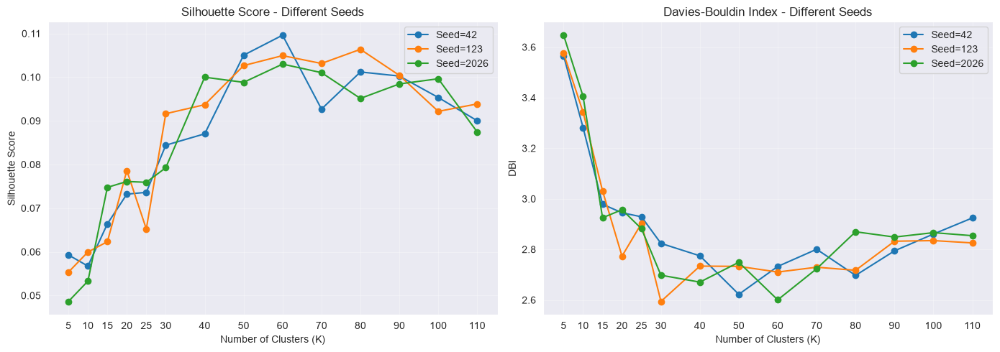

In [70]:
k_values = [5, 10, 15, 20, 25, 30, 40, 50, 60,
            70, 80, 90, 100, 110]

all_results = {}

for seed in RANDOM_SEEDS:
    print(f"\n========== SEED = {seed} ==========")

    silhouette_scores = []
    dbi_scores = []

    for k in k_values:
        kmeans = MiniBatchKMeans(
            n_clusters=k,
            random_state=seed,
            batch_size=2048,
            n_init=3
        )

        labels = kmeans.fit_predict(X_pca)

        sil = silhouette_score(
            X_pca,
            labels,
            sample_size=5000,
            random_state=42
        )

        dbi = davies_bouldin_score(
            X_pca,
            labels
        )

        silhouette_scores.append(sil)
        dbi_scores.append(dbi)

        print(f"K={k} | Silhouette={sil:.4f} | DBI={dbi:.4f}")

    all_results[seed] = {
        "silhouette": silhouette_scores,
        "dbi": dbi_scores
    }


# Plot results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for seed in RANDOM_SEEDS:
    axes[0].plot(
        k_values,
        all_results[seed]["silhouette"],
        marker="o",
        label=f"Seed={seed}"
    )

    axes[1].plot(
        k_values,
        all_results[seed]["dbi"],
        marker="o",
        label=f"Seed={seed}"
    )

axes[0].set_title("Silhouette Score - Different Seeds")
axes[0].set_ylabel("Silhouette Score")

axes[1].set_title("Davies-Bouldin Index - Different Seeds")
axes[1].set_ylabel("DBI")

for ax in axes:
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_xticks(k_values)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
بررسی پایداری خوشه‌بندی ResNet50 نسبت به تغییر Seed

به‌منظور بررسی پایداری خوشه‌بندی ویژگی‌های استخراج‌شده توسط ResNet50، الگوریتم MiniBatch K-Means با سه مقدار متفاوت برای `random_state` شامل 42، 123 و 2026 اجرا شد. در این آزمایش، مقادیر K از 5 تا 110 بررسی و معیارهای Silhouette Score و Davies-Bouldin Index مقایسه شدند.

نتایج نشان دادند که با وجود تفاوت‌هایی در مقادیر معیارها برای Seedهای مختلف، روند کلی منحنی‌ها نسبتاً مشابه است. در برخی مقادیر K اختلاف بیشتری مشاهده شد و بهترین مقادیر Silhouette و Davies-Bouldin نیز برای تمام Seedها دقیقاً در یک K به دست نیامدند.

در مجموع، نتایج نشان می‌دهند که خوشه‌بندی ویژگی‌های ResNet50 تا حدی نسبت به تغییر Seed پایدار است؛ بااین‌حال، مقداردهی اولیه الگوریتم می‌تواند بر کیفیت نهایی خوشه‌بندی اثر بگذارد.

</div>

# imbalance

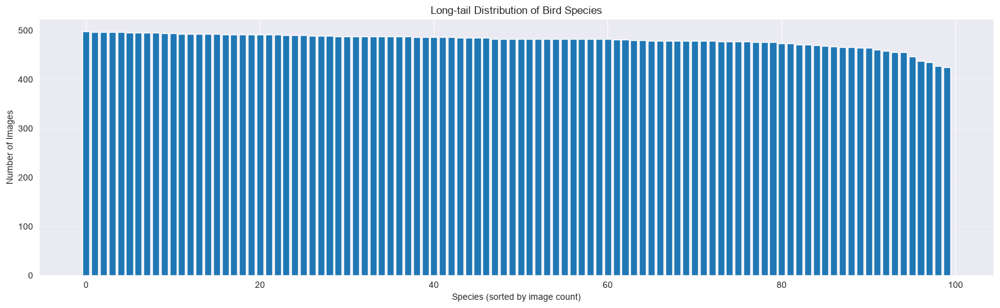

In [71]:
species_counts = (
    merged_df["species_scientific"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(16, 5))

plt.bar(
    range(len(species_counts)),
    species_counts.values
)

plt.xlabel("Species (sorted by image count)")
plt.ylabel("Number of Images")
plt.title("Long-tail Distribution of Bird Species")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [72]:
print("Number of species:", len(species_counts))
print("Minimum images:", species_counts.min())
print("Maximum images:", species_counts.max())
print("Mean images:", species_counts.mean())
print("Standard deviation:", species_counts.std())
print("Max / Min ratio:", species_counts.max() / species_counts.min())

Number of species: 100
Minimum images: 425
Maximum images: 498
Mean images: 480.53
Standard deviation: 14.331892105131525
Max / Min ratio: 1.171764705882353


<div dir="rtl" style="text-align: right;">
بررسی عدم‌توازن کلاس‌ها و توزیع دنباله‌بلند

برای بررسی توزیع کلاس‌ها، تعداد تصاویر مربوط به هر یک از ۱۰۰ گونه محاسبه شد. تعداد تصاویر هر گونه بین ۴۲۵ تا ۴۹۸ تصویر متغیر بود و میانگین تعداد تصاویر برابر با ۴۸۰٫۵۳ به دست آمد. همچنین انحراف معیار ۱۴٫۳۳ و نسبت بیشترین تعداد تصاویر به کمترین تعداد برابر با ۱٫۱۷ بود.

این نتایج نشان می‌دهند که مجموعه‌داده از نظر تعداد تصاویر کلاس‌ها توزیع نسبتاً متوازنی دارد و نشانه‌ای از عدم‌توازن شدید یا توزیع دنباله‌بلند کلاسیک در آن مشاهده نمی‌شود. بنابراین، انتظار نمی‌رود اختلاف تعداد نمونه‌های کلاس‌ها عامل اصلی غالب شدن برخی گونه‌ها در خوشه‌بندی باشد.
</div>

# outliers based on clustering

In [74]:
merged_df = merged_df.merge(
    df[["image_path", "sharpness", "bird_area_frac"]],
    on="image_path",
    how="left"
)

# Distance from each image to its assigned cluster center
cluster_labels = merged_df["cluster"].to_numpy()
cluster_centers = kmeans_final.cluster_centers_

distances = np.linalg.norm(
    X_pca - cluster_centers[cluster_labels],
    axis=1
)

merged_df["cluster_distance"] = distances

# Rank distances within each cluster
merged_df["outlier_score"] = (
    merged_df.groupby("cluster")["cluster_distance"]
    .rank(pct=True)
)

# Select 20 most unusual samples
outliers = (
    merged_df
    .sort_values("outlier_score", ascending=False)
    .head(20)
)

print(
    outliers[
        [
            "image_path",
            "species_scientific",
            "cluster",
            "cluster_distance",
            "outlier_score",
            "sharpness",
            "bird_area_frac"
        ]
    ].to_string(index=False)
)


                                                 image_path       species_scientific  cluster  cluster_distance  outlier_score  sharpness  bird_area_frac
       ../inat_birds\images/Buteo_jamaicensis/713761185.jpg        Buteo jamaicensis       28         19.415321            1.0     496.75         0.05142
       ../inat_birds\images/Turdus_philomelos/676054907.jpg        Turdus philomelos       39         14.540737            1.0    3077.46         0.11284
        ../inat_birds\images/Sturnus_vulgaris/691794046.jpg         Sturnus vulgaris       36         19.379240            1.0     567.02         0.08541
          ../inat_birds\images/Cygnus_atratus/740348952.jpg           Cygnus atratus       20         10.525860            1.0    4105.61         0.17984
           ../inat_birds\images/Gallus_gallus/755773439.jpg            Gallus gallus       35         10.608276            1.0    3451.75         0.09961
   ../inat_birds\images/Haematopus_ostralegus/695023916.jpg    Haematopus os

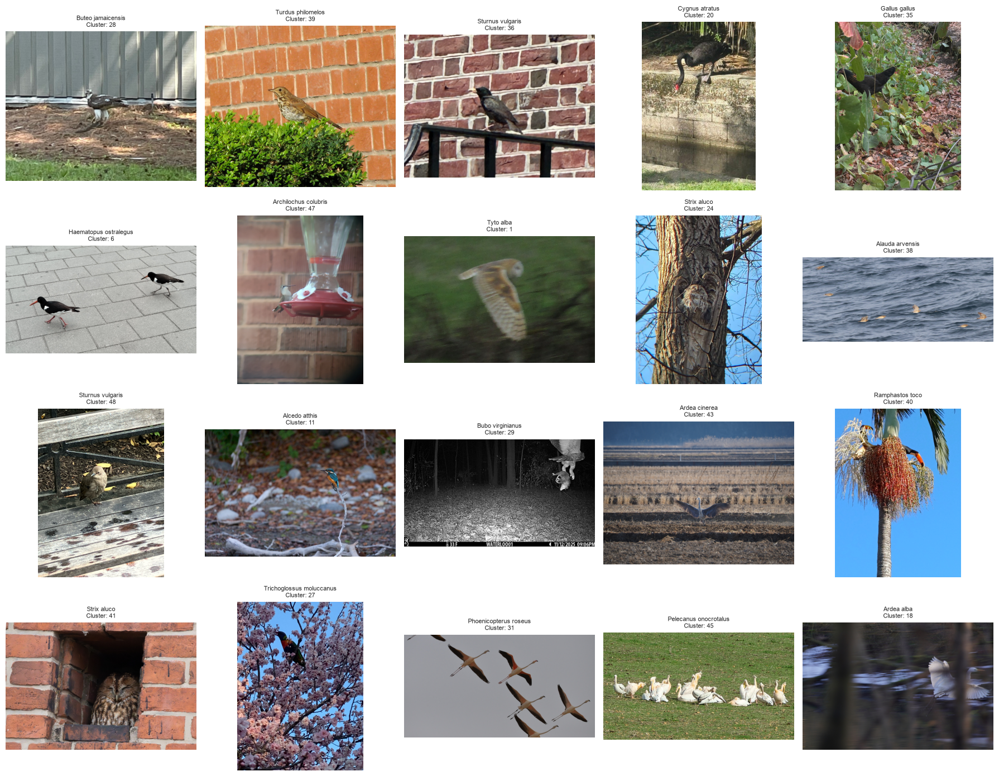

In [75]:
fig, axes = plt.subplots(4, 5, figsize=(18, 14))

for ax, (_, row) in zip(axes.flat, outliers.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(
        f'{row["species_scientific"]}\n'
        f'Cluster: {row["cluster"]}',
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
شناسایی و بررسی نمونه‌های غیرمعمول (Outliers)

برای شناسایی نمونه‌های غیرمعمول، فاصله‌ی Embedding هر تصویر تا مرکز خوشه‌ی اختصاص‌یافته به آن محاسبه شد. سپس ۲۰ نمونه با بیشترین فاصله‌ی نسبی از مرکز خوشه انتخاب و ویژگی‌های کیفی آن‌ها، از جمله Sharpness و Bird Area Fraction، بررسی شد.

بررسی تصاویر نشان داد که برخی نمونه‌ها دارای شرایط بصری غیرمعمول هستند؛ از جمله وجود اشیا در پیش‌زمینه که بخشی از بدن پرنده را می‌پوشانند (Occlusion). چنین عواملی می‌توانند نمایش ویژگی‌های تصویر توسط ResNet50 را تحت تأثیر قرار دهند و باعث افزایش فاصله‌ی آن از مرکز خوشه شوند.

به‌طور کلی، نمونه‌های دورافتاده لزوماً ناشی از خطای برچسب نیستند و می‌توانند به دلایلی مانند انسداد، کیفیت پایین تصویر یا تفاوت‌های طبیعی زیستی ایجاد شده باشند. بنابراین، بررسی بصری این نمونه‌ها برای تشخیص علت احتمالی دورافتادگی ضروری است.
</div>